# 08. Avaliação final do RAG de legislação

Avaliar as nove perguntas de teste congeladas no 05, com o modelo, prompt e recuperação fixados no 07. O fluxo executa busca em D no pgvector, HyDE, RRF, reranking e expansão para artigos A, respeitando o orçamento do Qwen.

As respostas são geradas pelo Ollama. Não há respostas simuladas, aprovação automática, taxa de alucinação fixa ou gabarito no prompt. Recuperação, execução técnica, citações formais e revisão jurídica são avaliadas separadamente. As correções do desenvolvimento não são usadas como respostas prontas para o teste.

Depois de observar o teste, não ajustar o sistema para melhorar o resultado deste mesmo conjunto e chamá-lo de avaliação cega. Uma nova rodada exige versionamento e relato explícito.


## 1. Configuração e proteção do teste

Por padrão, as células leem resultados existentes. Ative `RUN_FINAL_TEST = True` somente para executar o lote real, com o 07 parado. O lote salva cada resposta e preserva resultados anteriores, inclusive falhas, sem tentativas automáticas de correção com gabarito.


In [1]:
from pathlib import Path
import importlib
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.core.display import Markdown

EVAL_ROOT = next((base for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (base / 'src/rag/evaluation_08.py').is_file()), None)
if EVAL_ROOT is None:
    raise FileNotFoundError('Raiz do projeto não encontrada.')
if str(EVAL_ROOT) not in sys.path:
    sys.path.insert(0, str(EVAL_ROOT))
import src.rag.evaluation_08 as evaluation_08
importlib.reload(evaluation_08)

RUN_FINAL_TEST = True
frozen_08 = evaluation_08.validate_frozen(EVAL_ROOT, check_ollama=RUN_FINAL_TEST)
FINAL_REPORT_08 = evaluation_08.output_folder(EVAL_ROOT, frozen_08)
print('Configuração congelada validada:', frozen_08['configuracao_sha256'])
print('Modelo:', frozen_08['configuracao']['modelo_gerador']['nome'])
print('Recuperação: pgvector D → HyDE + RRF + reranking → artigos A.')
print('Respostas e revisões do desenvolvimento preservadas. Embeddings do corpus serão reutilizados.')


Configuração congelada validada: 2318200177f97e4df627986194bbba9cdaecd7fe2bdd8354fe3293b725734f1e
Modelo: qwen3:4b-instruct
Recuperação: pgvector D → HyDE + RRF + reranking → artigos A.
Respostas e revisões do desenvolvimento preservadas. Embeddings do corpus serão reutilizados.


## 2. Validar a identidade do teste

Confere perguntas, referências, aprovação e separação do desenvolvimento contra o hash congelado no 05. Não exibe o gabarito nesta etapa. As referências são acessadas somente pelo avaliador; o gerador recebe apenas a pergunta e o contexto recuperado.


In [2]:
if EVAL_ROOT is None:
    raise FileNotFoundError('Execute a configuração do 08.')
df_test_08, df_refs_test_08, test_hash_08 = evaluation_08.load_test(EVAL_ROOT)
print('Teste validado:', len(df_test_08), 'perguntas.')
print('Hash do teste:', test_hash_08)
display(df_test_08.groupby('rotulo_resposta').size().rename('quantidade').to_frame())


Teste validado: 9 perguntas.
Hash do teste: 7d094eddf4d34e7e3ce0cc39045b425630170b501b20a8a29ed236500b5e8b74


,quantidade
rotulo_resposta,
respondível,7
sem_resposta,2


## 3. Recuperação e geração reais

Requer PostgreSQL disponível, modelos locais do Sentence Transformers e Ollama com o digest congelado. O carregador reutiliza as definições do 06 e do 07; o teste não fornece referências esperadas à busca, ao HyDE ou à geração. Validações históricas do desenvolvimento continuam sendo executadas pelos carregadores reutilizados.

As falhas são registradas como falhas técnicas. Os resultados salvos incluem fontes, omissões de artigos por orçamento, tokens, tempos, utilização de cache, hashes e alertas formais. A geração não recebe feedback de revisão no teste.


In [3]:
if EVAL_ROOT is None:
    raise FileNotFoundError('Execute a configuração do 08.')
if RUN_FINAL_TEST:
    resultados_08 = evaluation_08.run_test(EVAL_ROOT, frozen_08, df_test_08)
else:
    saved_08 = FINAL_REPORT_08 / 'respostas_teste.json'
    resultados_08 = evaluation_08.read(saved_08) if saved_08.exists() else []
    print('Modo de leitura: nenhuma nova resposta gerada; resultados existentes preservados.')
    if not resultados_08:
        print('O teste real ainda não foi executado para esta configuração. Nenhum resultado foi simulado.')
if resultados_08:
    display(pd.DataFrame(resultados_08)[['query_id', 'status_execucao', 'tempo_total_observado_ms']])


q_test_01: resultado existente preservado (concluida).
q_test_02: resultado existente preservado (concluida).
q_test_03: resultado existente preservado (concluida).
q_test_04: resultado existente preservado (concluida).
q_test_05: resultado existente preservado (concluida).
q_test_06: resultado existente preservado (concluida).
q_test_07: resultado existente preservado (concluida).
q_test_08: resultado existente preservado (concluida).
q_test_neg_02: resultado existente preservado (concluida).


,query_id,status_execucao,tempo_total_observado_ms
0,q_test_01,concluida,193591.4370
1,q_test_02,concluida,250674.7589
2,q_test_03,concluida,159707.2387
3,q_test_04,concluida,190379.5769
4,q_test_05,concluida,252532.7039
5,q_test_06,concluida,241571.1299
6,q_test_07,concluida,243539.9625
7,q_test_08,concluida,289414.7389
8,q_test_neg_02,concluida,233817.3279


## 4. Métricas reais da recuperação e volume entregue

Hit@3, Recall@3, MRR@3 e nDCG@3 usam relevância binária por norma e posição exata do dispositivo, com deduplicação por artigo. A cobertura literal exige o trecho de evidência no artigo correspondente entre as fontes efetivamente enviadas ao modelo, depois do orçamento. A média é macro por pergunta respondível; não representa qualidade jurídica da resposta.

Casos sem resposta não recebem acerto de recuperação artificial. Respostas não executadas não produzem métricas finais. Falhas de recuperação nas perguntas respondíveis contam como zero; uma falha de geração pode conservar a recuperação que já ocorreu e continua registrada separadamente.


In [4]:
if EVAL_ROOT is None:
    raise FileNotFoundError('Execute a configuração do 08.')
df_metrics_08, summary_08 = evaluation_08.evaluate(
    EVAL_ROOT, frozen_08, df_test_08, df_refs_test_08, resultados_08)
display(df_metrics_08)
display(pd.Series(summary_08, name='resultado').to_frame())
print('Taxa de alucinação e acurácia jurídica não são inferidas automaticamente.')


,query_id,rotulo_resposta,status_execucao,fontes_entregues,caracteres_contexto,hit,recall,mrr,ndcg,cobertura_evidencias,tokens_entrada,tokens_saida,tempo_total_observado_ms,tempo_geracao_servidor_ms,cache_hit,recuperacao_cache_hit,alertas_formais
0,q_test_01,respondível,concluida,3,5962,1.0,1.0,1.0,1.0,1.0,3838,686,193591.4370,17617.709000,False,False,0
1,q_test_02,respondível,concluida,3,8614,1.0,1.0,1.0,1.0,1.0,4794,843,250674.7589,23532.888000,False,False,0
2,q_test_03,respondível,concluida,3,2958,1.0,1.0,1.0,1.0,1.0,2705,1061,159707.2387,28830.993000,False,False,0
3,q_test_04,respondível,concluida,3,2103,1.0,1.0,1.0,1.0,1.0,2512,979,190379.5769,26538.188000,False,False,0
4,q_test_05,sem_resposta,concluida,3,9190,NaN,NaN,NaN,NaN,NaN,5116,310,252532.7039,10983.943000,False,False,1
5,q_test_06,respondível,concluida,3,7298,1.0,1.0,1.0,1.0,1.0,4262,1253,241571.1299,41429.862000,False,False,0
6,q_test_07,respondível,concluida,2,4659,1.0,1.0,1.0,1.0,1.0,3218,1125,243539.9625,33155.180999,False,False,1
7,q_test_08,respondível,concluida,3,6648,1.0,1.0,1.0,1.0,1.0,4049,1610,289414.7389,48286.771000,False,False,0
8,q_test_neg_02,sem_resposta,concluida,3,2041,NaN,NaN,NaN,NaN,NaN,2576,322,233817.3279,9785.425000,False,False,1


,resultado
hit,1.0
recall,1.0
mrr,1.0
ndcg,1.0
cobertura_evidencias,1.0
total,9
concluidas,9
perguntas_respondiveis,7
casos_sem_resposta,2
falhas,0


Taxa de alucinação e acurácia jurídica não são inferidas automaticamente.


## 5. Perguntas, respostas e fontes para conferência

Saídas reais do teste, sem modificar a resposta do modelo. As fontes foram entregues na geração; o documento HyDE é sintético e não é evidência. A ausência de alerta formal não equivale à aprovação jurídica.


In [5]:
if not resultados_08:
    print('Não há respostas reais salvas para exibir.')
else:
    for result_08 in resultados_08:
        display(Markdown('### ' + result_08['query_id']))
        display(Markdown('**Pergunta:** ' + result_08['pergunta']))
        display(Markdown('**Execução:** ' + result_08['status_execucao']))
        if result_08['status_execucao'] == 'concluida':
            display(Markdown('**Resposta do modelo:**\n\n' + result_08['resposta']))
            display(pd.DataFrame([{
                'fonte': s['source_id'], 'norma': s.get('caminho_relativo'),
                'dispositivo': s.get('artigo_ref'), 'origem': s.get('source')
            } for s in result_08['sources']]))
            print('Alertas formais:', result_08.get('alertas_formais', []))
            print('Artigos omitidos por orçamento:', result_08.get('omitted', []))
        else:
            print(result_08.get('erro', 'Falha técnica registrada.'))


### q_test_01

**Pergunta:** Que exigência o art. 60 da CLT estabelece para a prorrogação de jornada em atividades insalubres e que exceção registra?

**Execução:** concluida

**Resposta do modelo:**

**Resposta direta:**  
O Art. 60 da CLT estabelece que, em atividades insalubres, **qualquer prorrogação da jornada de trabalho só poderá ser acordada mediante licença prévia das autoridades competentes em matéria de higiene do trabalho**. Essas autoridades devem realizar exames locais e verificar os métodos e processos de trabalho, diretamente ou por meio de órgãos sanitários federais, estaduais ou municipais.  

A exceção registrada no mesmo artigo é: **as jornadas de doze horas de trabalho por trinta e seis horas ininterruptas de descanso**, que **não exigem licença prévia**.

---

**Fundamentação:**  
A exigência de licença prévia para prorrogação de jornada em atividades insalubres é prevista no **Art. 60 da CLT**, que diz: *"Nas atividades insalubres... quaisquer prorrogações só poderão ser acordadas mediante licença prévia das autoridades competentes em matéria de higiene do trabalho..."* [Fonte 1].  

Esse dispositivo garante que a extensão da jornada de trabalho em ambientes insalubres seja avaliada por órgãos especializados, com o objetivo de proteger a saúde dos trabalhadores.  

A exceção mencionada é expressa no **Parágrafo Único do Art. 60**, que afirma: *"Excetuam-se da exigência de licença prévia as jornadas de doze horas de trabalho por trinta e seis horas ininterruptas de descanso"* [Fonte 1].  

Essa exceção é importante porque permite que, em certas condições específicas (jornada de 12 horas com 36 horas de descanso contínuas), a empresa possa estender a jornada sem precisar obter autorização prévia das autoridades de higiene do trabalho.  

> ⚠️ **Observação:** A pergunta não menciona o tipo de atividade, a condição do empregado ou o contexto específico do trabalho (ex: se é insalubre ou não). A resposta se baseia apenas no texto do Art. 60, que se aplica a atividades insalubres conforme definidas nos quadros do capítulo "Da Segurança e da Medicina do Trabalho". Caso o tipo de atividade não seja insalubre, a exigência de licença prévia não se aplica.  

Se o usuário quiser, posso ajudar a verificar se uma atividade específica é considerada insalubre, com base nos quadros da CLT.  

> ⚠️ **Limitação:** A resposta não pode afirmar que uma jornada específica é ou não insalubre sem conhecer os detalhes da atividade. A CLT define atividades insalubres por meio de quadros, que não foram fornecidos aqui.  

Portanto, a análise se limita ao que está escrito no Art. 60, com base nas fontes disponíveis.

,fonte,norma,dispositivo,origem
0,Fonte 1,codigos/consolidacao-das-leis-do-trabalho-clt-...,Art. 60,https://www.planalto.gov.br/ccivil_03/Decreto-...
1,Fonte 2,codigos/consolidacao-das-leis-do-trabalho-clt-...,Art. 61,https://www.planalto.gov.br/ccivil_03/Decreto-...
2,Fonte 3,codigos/consolidacao-das-leis-do-trabalho-clt-...,Art. 611-A,https://www.planalto.gov.br/ccivil_03/Decreto-...


Alertas formais: []
Artigos omitidos por orçamento: []


... (44 outputs left out)

**Execução:** concluida

**Resposta do modelo:**

Essa não é uma pergunta ligada ao Direito do Trabalho.  

A pergunta solicitada trata de um "processo" e de "sentença", referindo-se ao Código de Processo Civil, o que indica um contexto jurídico de processo civil, não de relações de trabalho. Como o usuário não mencionou uma situação de emprego, desligamento, contrato de trabalho, direitos trabalhistas ou qualquer outro tema ligado ao Direito do Trabalho, a pergunta está fora do escopo do Direito do Trabalho.

Se a sua intenção era entender o fundamento jurídico de uma sentença em um processo trabalhista (como por exemplo, a justificativa de um desligamento, a validade de um contrato, ou o direito à rescisão), por favor, forneça mais detalhes sobre o tipo de situação trabalhista (ex: rescisão contratual, demissão sem justa causa, direito à verba de rescisão, etc.) e os fatos específicos do caso.

Até então, não há evidência de que o processo em questão seja de Direito do Trabalho, e, portanto, não é possível identificar o fundamento jurídico da sentença com base nas evidências fornecidas.  

Se desejar, posso ajudar com uma análise jurídica no âmbito do Direito do Trabalho, desde que você forneça os detalhes do caso específico.

,fonte,norma,dispositivo,origem
0,Fonte 1,codigos/codigo-de-processo-civil-lei-13105-201...,Art. 426,https://www.planalto.gov.br/ccivil_03/_Ato2015...
1,Fonte 2,codigos/codigo-de-processo-civil-lei-13105-201...,Art. 398,https://www.planalto.gov.br/ccivil_03/_Ato2015...
2,Fonte 3,codigos/codigo-de-processo-civil-lei-13105-201...,Art. 203,https://www.planalto.gov.br/ccivil_03/_Ato2015...


Alertas formais: ['sem_citacao_explicita_revisar']
Artigos omitidos por orçamento: []


## 6. Revisão humana do teste

Preencha o CSV exportado após a geração: `decisao` (`aprovada` ou `reprovada`), suporte nas fontes, correção das citações, conduta, recusa quando aplicável, motivo e revisor. Confira fatos essenciais, limites da resposta, escopo trabalhista e ausência de promessa de resultado. Não confunda caso sem evidência na base com pergunta fora do Direito do Trabalho.

Cada decisão pertence ao hash da resposta e à configuração testada. As revisões do desenvolvimento não aprovam automaticamente as respostas do teste. A revisão serve à avaliação final, não à correção do mesmo lote com o gabarito.


In [6]:
if EVAL_ROOT is None:
    raise FileNotFoundError('Execute a configuração do 08.')
review_path_08 = evaluation_08.export_review_template(EVAL_ROOT, frozen_08, df_test_08, resultados_08)
if resultados_08:
    display(df_test_08[['query_id', 'rotulo_resposta', 'pontos_esperados', 'limites_resposta']])
    if review_path_08.exists():
        df_review_08 = pd.read_csv(review_path_08, keep_default_na=False)
        display(df_review_08)
        print('Arquivo para revisão:', review_path_08)
else:
    print('A ficha de revisão será criada quando houver respostas reais concluídas.')


,query_id,rotulo_resposta,pontos_esperados,limites_resposta
0,q_test_01,respondível,Indicar a licença prévia e a finalidade dos ex...,Não confundir atividade insalubre com ausência...
1,q_test_02,respondível,"Indicar adiantamentos, lei ou contrato coletiv...","Não inferir percentual de vale-transporte, que..."
2,q_test_03,respondível,"Indicar o acréscimo mínimo de 20%, hora de 52 ...","Descrever o corpus, sem validar a aplicabilida..."
3,q_test_04,respondível,Indicar confirmação da gravidez durante contra...,Não inventar a duração da estabilidade a parti...
4,q_test_05,sem_resposta,Reconhecer insuficiência de suporte no corpus ...,"Não inventar valores, decisões individuais ou ..."
5,q_test_06,respondível,Definir tempo à disposição conforme caput e di...,Não decidir horas extras de um trabalhador sem...
6,q_test_07,respondível,Distinguir remuneração/salário e gorjetas no a...,Não classificar automaticamente pagamentos de ...
7,q_test_08,respondível,Enumerar as ausências e respectivos períodos/c...,Não ampliar prazos ou criar dispensas não desc...
8,q_test_neg_02,sem_resposta,Reconhecer insuficiência de suporte no corpus ...,"Não inventar valores, decisões individuais ou ..."


,query_id,resposta_sha256,configuracao_sha256,escopo_decisao,decisao,suporte_fontes,citacoes_corretas,conduta_adequada,recusa_adequada_se_aplicavel,motivo,resposta_corrigida_revisora,revisor
0,q_test_01,869258e4b63f3c3181383200e57c45d04ede3281037813...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,aprovada,,O que está certo\n\nA “Resposta direta” cobre ...,AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CON...,,Fonte 1: Acrescentasse o marco da Lei 13.467/2017,Ajustar:\n\nOs dois avisos finais são indevido...,Laisa
1,q_test_02,5b0b98874a6f5f54ff386e1c6d418e1590618f2164a0d1...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,aprovada,Acerta a lista de hipóteses e a existência das...,está certo::\n\nOs três casos do caput: adiant...,AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CON...,"Para o caso do vale-transporte, a recusa vale ...",,Adiantamentos mal explicados. O texto diz “emp...,Laisa
2,q_test_03,dfe1de3fc4ba8b3d318eb5fe300264c9630e08a958cd6e...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,reprovada,"s três números centrais estão certos, mas a re...",Acréscimo mínimo de 20% sobre a hora diurna.\n...,AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CON...,,,Erros a corrigir\n\nDispositivo errado para os...,Laisa
3,q_test_04,66c5118ad505e26161952b43c8321bf36503bad31777c9...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,aprovada,correta no conteúdo central. Eu enxugaria o te...,A confirmação da gravidez no curso do contrato...,AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CON...,,,Imprecisões a ajustar\n\n“Impede que o emprega...,Laisa
4,q_test_05,c8458152fa54ac9a23cc7649bf13bb1c03f91780bd0366...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,reprovada,,Reconhece que as fontes entregues (Lei 8.212/1...,AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO ...,,Parcialmente adequada. Chega à conclusão certa...,Problemas a corrigir\n\nA frase de abertura es...,Laisa
5,q_test_06,43da6e92340d6cac4c4a45384e7e797f3b1e9caa392da3...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,aprovada,,A definição do caput: serviço efetivo é o perí...,AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO ...,,Parcialmente adequada. O esqueleto está certo ...,Erros e imprecisões a corrigir\n\n“Apenas quan...,Laisa
6,q_test_07,39a8c7c0cf1c66bc8d3dfaa16a0a0b87b10df49f192e38...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,aprovada,,O que está certo\n\nA lista do § 2º do art. 45...,AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO ...,,Parcialmente adequada. Os dispositivos certos ...,Erros e imprecisões a corrigir\n\nConfusão ent...,Laisa
7,q_test_08,e163fa0869401b4bd6075ec23ef1b3ca7c9846a1b1397b...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,aprovada,,"O que está certo\n\nOs incisos I a XII, com se...",AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO ...,,Parcialmente adequada. A lista dos 12 incisos ...,O art. 473 da CLT permite que o empregado deix...,Laisa
8,q_test_neg_02,e2d39e28f58cdc0a4944969b5ba15bc0b1137fac21cf01...,2318200177f97e4df627986194bbba9cdaecd7fe2bdd83...,resposta_original_do_modelo,reprovada,,"Não inventa fundamento, valor ou decisão.\nRec...",AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO ...,,Parcialmente adequada. A conclusão (não dá par...,Versão mais adequada\n\nNão consigo dizer qual...,Laisa


Arquivo para revisão: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\legislacao\avaliacao_final\2318200177f97e4df627986194bbba9cdaecd7fe2bdd8354fe3293b725734f1e\revisao_juridica_teste.csv


### Sua avaliação — `q_test_01`

**Pergunta:** Que exigência o art. 60 da CLT estabelece para a prorrogação de jornada em atividades insalubres e que exceção registra?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
**Resposta direta:**  
O Art. 60 da CLT estabelece que, em atividades insalubres, **qualquer prorrogação da jornada de trabalho só poderá ser acordada mediante licença prévia das autoridades competentes em matéria de higiene do trabalho**. Essas autoridades devem realizar exames locais e verificar os métodos e processos de trabalho, diretamente ou por meio de órgãos sanitários federais, estaduais ou municipais.  

A exceção registrada no mesmo artigo é: **as jornadas de doze horas de trabalho por trinta e seis horas ininterruptas de descanso**, que **não exigem licença prévia**.

---

**Fundamentação:**  
A exigência de licença prévia para prorrogação de jornada em atividades insalubres é prevista no **Art. 60 da CLT**, que diz: *"Nas atividades insalubres... quaisquer prorrogações só poderão ser acordadas mediante licença prévia das autoridades competentes em matéria de higiene do trabalho..."* [Fonte 1].  

Esse dispositivo garante que a extensão da jornada de trabalho em ambientes insalubres seja avaliada por órgãos especializados, com o objetivo de proteger a saúde dos trabalhadores.  

A exceção mencionada é expressa no **Parágrafo Único do Art. 60**, que afirma: *"Excetuam-se da exigência de licença prévia as jornadas de doze horas de trabalho por trinta e seis horas ininterruptas de descanso"* [Fonte 1].  

Essa exceção é importante porque permite que, em certas condições específicas (jornada de 12 horas com 36 horas de descanso contínuas), a empresa possa estender a jornada sem precisar obter autorização prévia das autoridades de higiene do trabalho.  

> ⚠️ **Observação:** A pergunta não menciona o tipo de atividade, a condição do empregado ou o contexto específico do trabalho (ex: se é insalubre ou não). A resposta se baseia apenas no texto do Art. 60, que se aplica a atividades insalubres conforme definidas nos quadros do capítulo "Da Segurança e da Medicina do Trabalho". Caso o tipo de atividade não seja insalubre, a exigência de licença prévia não se aplica.  

Se o usuário quiser, posso ajudar a verificar se uma atividade específica é considerada insalubre, com base nos quadros da CLT.  

> ⚠️ **Limitação:** A resposta não pode afirmar que uma jornada específica é ou não insalubre sem conhecer os detalhes da atividade. A CLT define atividades insalubres por meio de quadros, que não foram fornecidos aqui.  

Portanto, a análise se limita ao que está escrito no Art. 60, com base nas fontes disponíveis.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 60
- [Fonte 2] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 61
- [Fonte 3] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 611-A

**Pontos esperados para avaliação:** Indicar a licença prévia e a finalidade dos exames; registrar a exceção de doze horas por trinta e seis do parágrafo único.

**Limites da resposta:** Não confundir atividade insalubre com ausência por doença nem extrapolar para licenciamento de um caso concreto.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** APROVADA

**Suporte nas fontes:** 

**Citações corretas:** O que está certo

A “Resposta direta” cobre os dois pontos pedidos: a licença prévia das autoridades de higiene do trabalho para qualquer prorrogação em atividade insalubre, e a exceção do 12x36 no parágrafo único.
A citação do caput e do parágrafo único confere com o texto legal.
A menção a exames locais e à verificação dos métodos e processos de trabalho está correta.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CONTEXTO DA RESPOSTA.

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:**  Fonte 1: Acrescentasse o marco da Lei 13.467/2017

**Resposta corrigida pela revisora:** Ajustar:

Os dois avisos finais são indevidos. A pergunta já diz “atividades insalubres”, então a observação de que ela “não menciona se é insalubre ou não” contradiz o enunciado. A “Limitação” sobre não saber se uma jornada específica é insalubre também não se aplica, porque ninguém perguntou isso. Os dois avisos só confundem.
A oferta final está mal formulada. “Se o usuário quiser, posso ajudar...” fala do usuário em terceira pessoa, num texto dirigido a ele.
A Fundamentação repete a resposta direta. Reproduz as mesmas citações sem acrescentar nada.
A explicação da exceção é imprecisa. O texto diz que a empresa “possa estender a jornada” sem licença. O 12x36 é um regime de jornada e descanso, e a exceção dispensa a licença prévia para adotá-lo em ambiente insalubre. Não se trata de estender a jornada.
Falta contexto. A resposta não diz que o parágrafo único veio com a Lei 13.467/2017 (reforma trabalhista), vigente desde 11/11/2017. Também não cita o art. 611-A, XIII, e a jurisprudência do TST, que interpreta a exceção restritivamente (só 12x36) e a aplica a partir da reforma. Para uma pergunta curta de prova isso pode ser opcional, mas para uma resposta útil vale pelo menos uma linha.

**Revisor(a):** Laisa


### Sua avaliação — `q_test_02`

**Pergunta:** Quais descontos salariais são admitidos e quais condições para desconto por dano são descritas no art. 462 da CLT?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
**Resposta direta:**  
Segundo o **Art. 462 da CLT**, os descontos salariais são **admitidos apenas em três casos específicos**:  
1. Quando resultam de **adiantamentos** (ex: empréstimo de dinheiro pelo empregado);  
2. Quando previstos por **dispositivos de lei**;  
3. Quando estabelecidos por **contrato coletivo**.  

Além disso, **é lícito descontar por dano causado pelo empregado**, **mas apenas se**:  
- O desconto foi **acordado previamente**, ou  
- O empregado cometeu **dolo** (intenção de causar dano).  

Essas regras estão descritas no **Art. 462, § 1º**, da CLT.  

---

**Fundamentação:**  
O **Art. 462 da CLT** (disponível em https://www.planalto.gov.br/ccivil_03/Decreto-Lei/Del5452compilado.htm) estabelece que o empregador é **vedado** efetuar descontos nos salários, **salvo** em casos específicos.  

O **dispositivo principal** (Art. 462) afirma que os descontos são permitidos apenas em:  
- Adiantamentos (ex: quando o empregado já pagou parte do salário);  
- Dispositivos legais (ex: impostos obrigatórios);  
- Contratos coletivos (ex: acordos entre empregadores e trabalhadores).  

O **§ 1º** do mesmo artigo trata do desconto por **dano causado pelo empregado**, com duas condições:  
1. O desconto deve ter sido **acordado previamente**;  
2. O dano deve ter sido causado por **dolo** (intenção de prejudicar o empregador).  

Essas condições são **exclusivas** e **não podem ser aplicadas de forma arbitrária**.  

Importante: o **Art. 462, § 4º** afirma que **é vedado limitar a liberdade do empregado de dispensar seu salário**, o que reforça que os descontos devem ser justificados e não podem ser usados para coagir o trabalhador.  

**Fonte:** [Fonte 1] – Art. 462, § 1º da CLT.  

---

**Observação sobre limitações:**  
- A resposta se baseia apenas no **Art. 462**, e **não considera** outros fatores como o tipo de contrato, a data de admissão, ou o motivo do desligamento, que poderiam influenciar a aplicação prática.  
- Não há jurisprudência específica mencionada nas evidências para confirmar ou rejeitar essas regras em casos concretos.  
- A ausência de detalhes sobre o **tipo de dano**, **natureza do contrato**, ou **circunstâncias específicas** torna impossível uma análise mais aprofundada.  

Se o caso envolver **dano causado por ato do empregado**, é necessário verificar se houve **acordo prévio** ou **dolo**, conforme o Art. 462, § 1º.  

Se desejar, posso ajudar a analisar um caso específico com base em dados como:  
- O tipo de dano (ex: roubo, desvio de bens);  
- Se houve contrato de trabalho;  
- Se houve acordo prévio sobre descontos.  

Por favor, forneça essas informações para uma análise mais precisa.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 462
- [Fonte 2] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 461
- [Fonte 3] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 611-B

**Pontos esperados para avaliação:** Indicar adiantamentos, lei ou contrato coletivo; explicar acordo ou dolo para danos no § 1º e preservar as demais restrições do artigo quando pertinentes.

**Limites da resposta:** Não inferir percentual de vale-transporte, que não é fornecido pelo artigo; não aprovar desconto individual sem fatos.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** APROVADA

**Suporte nas fontes:** Acerta a lista de hipóteses e a existência das condições do § 1º, mas erra os exemplos de adiantamento e de contrato coletivo, cita errado o § 4º, trata as condições do dano como cumulativas e omite os §§ 2º e 3º

**Citações corretas:** está certo::

Os três casos do caput: adiantamentos, dispositivos de lei e contrato coletivo.
O § 1º como sede do desconto por dano.
A “Resposta direta” lista as condições do dano como alternativas (“acordado... ou dolo”), que é a leitura correta.
Não infere percentual de vale-transporte nem aprova desconto em caso concreto.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CONTEXTO DA RESPOSTA.


**Recusa adequada, quando aplicável:** Para o caso do vale-transporte, a recusa vale só dentro do escopo “o art. 462 e as fontes entregues”. Se o objetivo fosse responder sobre esse percentual em geral, a resposta teria de vir de outra norma, que não está nas fontes desse teste.

**Justificativa e observações:** 

**Resposta corrigida pela revisora:** Adiantamentos mal explicados. O texto diz “empréstimo de dinheiro pelo empregado” e “quando o empregado já pagou parte do salário”. Está invertido: adiantamento é o empregador antecipar valores ao empregado (adiantamento salarial, por exemplo), que depois são descontados.
Contrato coletivo mal explicado. “Acordos entre empregadores e trabalhadores” é impreciso. A previsão decorre de norma coletiva (convenção ou acordo coletivo), firmada com o sindicato. Um ajuste individual não se enquadra aqui.
Citação errada do § 4º. O texto legal diz que é vedado limitar a liberdade do empregado de dispor do seu salário, não de “dispensar”. A interpretação de que os descontos “não podem ser usados para coagir o trabalhador” também é uma extrapolação.
Inconsistência sobre o dano. A Fundamentação apresenta “acordado previamente” e “dolo” como “duas condições” numeradas e “exclusivas”, o que sugere que devem ocorrer juntas. A lei diz o contrário: o desconto é lícito se a possibilidade tiver sido acordada ou se houver dolo. Sem dolo, só vale se houver acordo prévio. Havendo dolo, o desconto é lícito mesmo sem acordo.

Omissões frente ao esperado

Faltam as demais restrições do artigo, que os pontos esperados pedem “quando pertinentes”: o § 2º (vedação de coação ou induzimento para uso de armazém ou serviços mantidos pela empresa) e o § 3º (medidas da autoridade para preços razoáveis, sem intuito de lucro, quando os empregados não têm acesso a armazéns ou serviços alternativos).
O caput diz que é vedado “qualquer desconto”. O texto poderia deixar claro que a regra é a vedação e que as hipóteses são exceções.

Ruídos a cortar

O link do Planalto não faz parte das fontes entregues, então a citação deveria ficar só em “Art. 462 (Fonte 1)”.
A seção “Observação sobre limitações” é desnecessária. Falar em tipo de contrato, data de admissão e motivo do desligamento não tem relação com a pergunta.
A oferta final pede dados como “se houve contrato de trabalho”, o que é óbvio e não ajuda.
A Fundamentação repete a resposta direta.
“O empregador é vedado efetuar” é erro de redação. O correto é “é vedado ao empregador efetuar”.

**Revisor(a):** Laisa


### Sua avaliação — `q_test_03`

**Pergunta:** Como é calculada a remuneração do trabalho noturno urbano em comparação ao diurno?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
A remuneração do trabalho noturno urbano é calculada com um acréscimo de pelo menos 20% sobre a remuneração da hora diurna.

[Fonte 1] e [Fonte 2] estabelecem que, para os efeitos do trabalho noturno urbano, o horário considerado noturno é entre as 22 horas de um dia e as 5 horas do dia seguinte. Nesse período, a hora de trabalho noturno terá duração de 52 minutos e 30 segundos, conforme previsto no § 1º das duas fontes.

O acréscimo sobre a remuneração diurna é de no mínimo 20%, conforme o Art. 73, § 2º da CLT (Fonte 1) e o Art. 14, § 2º da Lei Complementar 150/2015 (Fonte 2). Esse acréscimo é aplicado sobre o valor da hora diurna, não sobre o salário total, e é obrigatório para empresas que não mantêm trabalho noturno habitual, desde que o trabalho noturno seja de natureza semelhante ao diurno.

Importante: a remuneração noturna é calculada com base no valor da hora diurna, e não sobre o salário mensal ou o valor total do contrato. O acréscimo de 20% é o mínimo exigido pela legislação, e não pode ser menor.

**Fundamentação:**

- O Art. 73, § 2º da CLT (Fonte 1) estabelece que a hora do trabalho noturno será computada como de 52 minutos e 30 segundos, o que é um detalhe técnico de cálculo de horas, mas não altera o valor da remuneração.
- O Art. 73, § 3º da CLT (Fonte 1) e o Art. 14, § 3º da Lei Complementar 150/2015 (Fonte 2) indicam que, em empresas que não têm trabalho noturno habitual, o acréscimo é calculado com base nos quantitativos pagos por trabalhos diurnos semelhantes, mas o mínimo de 20% é mantido.
- O Art. 14, § 2º da Lei Complementar 150/2015 (Fonte 2) reafirma o acréscimo de 20% sobre a hora diurna, como exigido pela CLT, e aplica-se ao trabalho noturno urbano, pois o horário definido (22h a 5h) é o mesmo do Art. 73, § 2º.

**Observação importante:**  
A Lei 5.889/1973 (Fonte 3) trata de trabalho noturno em atividades rurais (lavoura e pecuária), com acréscimo de 25%, e **não se aplica ao trabalho urbano**. Portanto, não é relevante para o cálculo do trabalho noturno urbano.

**Conclusão:**  
Em relação ao trabalho noturno urbano, a remuneração é calculada com acréscimo de **no mínimo 20% sobre a hora diurna**, conforme previsto no Art. 73, § 2º da CLT e no Art. 14, § 2º da Lei Complementar 150/2015.

> ⚠️ **Limitação:**  
> Essa resposta se aplica apenas ao trabalho noturno urbano, com horário entre 22h e 5h. Não se aplica a atividades rurais, nem a trabalhadores domésticos que não atuam em horários noturnos definidos.  
> Além disso, a remuneração deve ser calculada sobre a **hora diurna**, não sobre o salário mensal, e o acréscimo é obrigatório, mesmo que o empregado trabalhe apenas em horários noturnos.  
>  
> **Não há evidência sobre casos específicos de empresas com atividades noturnas habituais ou de horários mistos com diferentes valores**, o que poderia exigir ajustes.  
>  
> Se o usuário quiser saber como o acréscimo é calculado em um caso específico (ex: empresa com horário misto, ou com trabalho noturno habitual), seria necessário fornecer mais detalhes (ex: tipo de atividade, horário exato, natureza do trabalho).  

Se desejar, posso ajudar a calcular o valor com base em um valor diurno fornecido.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 73
- [Fonte 2] leis-complementares/2015/lcp-150-2015.md — Art. 14
- [Fonte 3] leis/1973/lei-5889-1973.md — Art. 7º

**Pontos esperados para avaliação:** Indicar o acréscimo mínimo de 20%, hora de 52 minutos e 30 segundos e período de 22h a 5h; registrar as ressalvas textuais e horários mistos/prorrogações.

**Limites da resposta:** Descrever o corpus, sem validar a aplicabilidade atual de ressalvas históricas ou calcular valores individuais sem dados.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** REPROVADA

**Suporte nas fontes:** s três números centrais estão certos, mas a resposta troca os parágrafos do art. 73, inverte o conteúdo do § 3º (25%, não 20%), confunde a LC 150 com a regra geral urbana e omite a ressalva de revezamento, os horários mistos e as prorrogações

**Citações corretas:** Acréscimo mínimo de 20% sobre a hora diurna.
Período noturno de 22h às 5h.
Hora noturna de 52 min 30 s.
A Lei 5.889/1973 é tratada como rural (25%) e afastada, o que é correto.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CONTEXTO DA RESPOSTA.


**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** 

**Resposta corrigida pela revisora:** Erros a corrigir

Dispositivo errado para os 20%. O acréscimo está no caput do art. 73 da CLT, não no § 2º. O § 2º define o horário noturno (22h às 5h).
Parágrafo errado para a hora de 52min30s. Ela está no § 1º do art. 73. A Fundamentação cita o § 2º, contradizendo o próprio início da resposta, que citava o § 1º.
Descrição errada do § 3º, o erro mais grave. O § 3º diz que, para empresas que não mantenham, pela natureza de suas atividades, trabalho noturno habitual, o acréscimo é de 25% obrigatoriamente. A resposta diz que o cálculo usa “quantitativos pagos por trabalhos diurnos semelhantes” e que o mínimo de 20% se mantém, o que é invenção. A frase “desde que o trabalho noturno seja de natureza semelhante ao diurno” também não existe no texto.
A hora reduzida “não altera o valor da remuneração” é incorreto. A hora ficta de 52min30s encurta a hora de trabalho noturno, o que na prática aumenta o ganho. Ela é um mecanismo distinto do adicional de 20%, e ambos se somam.
A LC 150/2015 é tratada como regra do “trabalho urbano” em geral. Ela rege o empregado doméstico. A “Limitação” diz que não se aplica a domésticos “que não atuam em horários noturnos”, o que não faz sentido, porque quem trabalha à noite tem o adicional.

Omissões frente aos pontos esperados

Ressalva do caput do art. 73: “salvo nos casos de revezamento semanal ou quinzenal”. É a ressalva textual que o teste pede para registrar, sem validar sua aplicabilidade atual.
Horários mistos (art. 73, § 4º): as horas noturnas recebem o tratamento do artigo, e na LC 150 as horas diurnas e noturnas são apuradas separadamente.
Prorrogações (art. 73, § 5º): as prorrogações do trabalho noturno seguem as mesmas regras.
Regra do empregado contratado só para o período noturno na LC 150, em que o acréscimo incide sobre o salário anotado na CTPS. Confirme esse ponto no § 3º do art. 14, porque estou citando de memória e a fonte não aparece aqui.

Ruídos a cortar

A resposta repete duas ou três vezes que o acréscimo incide sobre a hora diurna “e não sobre o salário mensal”. A distinção é confusa e não vem do texto legal.
O bloco “Observação importante” e a “Limitação” são longos e misturam pontos que não têm relação com a pergunta.
A oferta final de calcular o valor está aceitável, mas sem dados do caso ela não deveria insinuar um cálculo.

**Revisor(a):** Laisa


### Sua avaliação — `q_test_04`

**Pergunta:** Como o art. 391-A da CLT trata a confirmação da gravidez durante o contrato e o aviso prévio?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
**Resposta direta:**  
O Art. 391-A da CLT garante à empregada gestante a **estabilidade provisória**, mesmo que a confirmação da gravidez ocorra durante o período do aviso prévio trabalhado ou indenizado. Esse direito se aplica tanto à empregada quanto ao empregado adotante que tenha sido concedida guarda provisória para fins de adoção [Fonte 1].

---

**Fundamentação:**  

O Artigo 391-A da CLT, que foi incluído pela Lei nº 12.812, de 2013, estabelece que, **quando a gravidez é confirmada durante o curso do contrato de trabalho**, independentemente do período em que o aviso prévio estiver em vigor (ou se for indenizado), a empregada gestante adquire a **estabilidade provisória** prevista na alínea "b" do inciso II do art. 10 do Ato das Disposições Constitucionais Transitórias (ADCT).  

Essa estabilidade provisória impede que o empregador resolva o contrato de trabalho por motivo de gravidez, mesmo que o aviso prévio esteja em curso. Isso significa que, se a gravidez for confirmada durante o período do aviso prévio, o empregador **não pode rescindir o contrato** por esse motivo, pois a empregada está protegida por essa norma.  

O parágrafo único do artigo estende esse princípio ao **empregado adotante** que tenha sido concedida guarda provisória para fins de adoção, garantindo-lhe a mesma proteção.  

Essa disposição está alinhada ao Art. 391 da CLT, que já previa que a gravidez não constitui justo motivo para rescisão do contrato, mas o Art. 391-A **reforça e amplia** essa proteção ao incluir a situação de confirmação da gravidez durante o aviso prévio, garantindo a estabilidade provisória.  

O Art. 25 da Lei Complementar 150/2015 (sobre trabalho doméstico) reforça esse direito, afirmando que a empregada doméstica gestante tem direito a licença-maternidade de 120 dias, com preservação do emprego e salário, e que a confirmação da gravidez durante o contrato garante a estabilidade provisória — o que confirma a aplicação do mesmo princípio no contexto doméstico [Fonte 2].

**Limitações:**  
- A resposta se baseia apenas na confirmação da gravidez durante o contrato, não em outros motivos de rescisão ou em situações específicas como demissão por justa causa, ausência de aviso prévio ou outros fatores.  
- Não há informação sobre o tipo de contrato (por exemplo, CLT, doméstico, por tempo determinado), mas o Art. 391-A se aplica ao trabalho geral, incluindo o doméstico, conforme o Art. 25.  
- A análise não considera se o aviso prévio foi cumprido ou se houve outro motivo de rescisão, o que poderia afetar a aplicação prática.  

**Conclusão:**  
O Art. 391-A da CLT **protege a empregada gestante** mesmo que a gravidez seja confirmada durante o período do aviso prévio, garantindo a estabilidade provisória, conforme previsto no art. 10, alínea "b", do ADCT.  

**Fontes:**  
- [Fonte 1] Art. 391-A da CLT  
- [Fonte 2] Art. 25 da LC 150/2015  

> ⚠️ **Observação:** Essa resposta não envolve dados pessoais, não faz previsão de decisão judicial específica e não garante o resultado de um processo individual. A aplicação prática pode depender de outros fatores (como o tipo de contrato, a data de admissão, o motivo da rescisão, etc.), que não foram fornecidos. Se houver necessidade de análise de caso específico, é necessário informar esses dados.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 391-A
- [Fonte 2] leis-complementares/2015/lcp-150-2015.md — Art. 25
- [Fonte 3] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 391

**Pontos esperados para avaliação:** Indicar confirmação da gravidez durante contrato ou aviso prévio trabalhado/indenizado e remissão à estabilidade do ADCT; distinguir parágrafo sobre adotante.

**Limites da resposta:** Não inventar a duração da estabilidade a partir desta evidência isolada nem concluir direito individual.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** APROVADA

**Suporte nas fontes:** correta no conteúdo central. Eu enxugaria o texto, trocaria “por motivo de gravidez” por uma formulação neutra (estabilidade contra dispensa sem justa causa), corrigiria a relação entre o 391-A e o art. 25 da LC 150, e removeria as limitações genéricas.

**Citações corretas:** A confirmação da gravidez no curso do contrato, inclusive durante o aviso prévio trabalhado ou indenizado, garante a estabilidade provisória do art. 10, II, “b”, do ADCT.
O parágrafo único estende a regra ao empregado adotante com guarda provisória para fins de adoção, e a resposta o distingue do caput.
A origem na Lei 12.812/2013 está correta.
A LC 150/2015, art. 25, é usada para o doméstico: licença-maternidade de 120 dias e estabilidade.
Não inventa a duração da estabilidade nem conclui direito individual, como os limites pedem.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA DO REVISOR AO CONTEXTO DA RESPOSTA.

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** 

**Resposta corrigida pela revisora:** Imprecisões a ajustar

“Impede que o empregador resolva o contrato por motivo de gravidez”. A estabilidade do ADCT protege contra a dispensa arbitrária ou sem justa causa, independentemente do motivo ou de o empregador saber da gravidez. Limitar à dispensa “por motivo de gravidez” estreita a regra.
“Independentemente do período em que o aviso prévio estiver em vigor”. A redação do artigo é “ainda que durante o prazo do aviso prévio trabalhado ou indenizado”. Convém manter essa formulação, que é mais fiel e mais clara.
“O Art. 391-A se aplica ao trabalho geral, incluindo o doméstico, conforme o Art. 25”. O doméstico tem regra própria no art. 25 da LC 150. O correto é dizer que o art. 25 prevê a mesma proteção para a doméstica, não que o 391-A se estende a ela por força do art. 25.
Relação com o art. 391. Dizer que o 391-A “reforça e amplia” o art. 391 é interpretação. O 391 diz que a gravidez não é justo motivo para rescisão, e o 391-A trata do momento da confirmação, inclusive no aviso prévio. Vale descrever isso sem o juízo de valor. Além disso, a Fonte 3 (art. 391) não foi citada na lista de fontes.

Ruídos a cortar

A seção “Limitações” e a “Observação” final (sobre “dados pessoais”, “previsão de decisão judicial”, tipo de contrato, data de admissão) não têm relação com a pergunta.
Os avisos sobre “justa causa” e “ausência de aviso prévio” são irrelevantes, e a oferta final de analisar caso específico é desnecessária.
A Fundamentação repete a resposta direta.

**Revisor(a):** Laisa


### Sua avaliação — `q_test_05`

**Pergunta:** Quais são as regras aplicáveis ao contrato de trabalho do atleta profissional de futebol nos EUA?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
Essa não é uma pergunta ligada ao Direito do Trabalho.  

O contrato de trabalho do atleta profissional de futebol nos EUA é regido por leis e regulamentações norte-americanas, como o **Labor Code** dos Estados Unidos, o **National Labor Relations Act**, ou acordos específicos entre clubes e atletas (como os acordos de contratação de atletas da NFL, NBA, etc.), e não por legislação brasileira, como a CLT ou a Lei 8.212/1991.  

As fontes fornecidas referem-se à **legislação brasileira** (CLT, Lei 8.212/1991), e **não têm aplicação nos EUA**.  

Portanto, não é possível aplicar nenhuma das regras presentes nas evidências ao contrato de trabalho de um atleta profissional de futebol nos EUA, pois:  
- As normas citadas são de **direito brasileiro**;  
- O contexto geográfico (EUA) e o tipo de atividade (futebol profissional) exigem uma análise jurídica específica e independente da legislação brasileira.  

Se desejar, posso ajudar com informações sobre o Direito do Trabalho nos EUA, desde que a pergunta seja sobre esse tema.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] leis/1991/lei-8212-1991.md — Art. 21
- [Fonte 2] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 75-B
- [Fonte 3] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 444

**Pontos esperados para avaliação:** Reconhecer insuficiência de suporte no corpus para a pergunta específica; explicar a limitação e solicitar a fonte ou os dados ausentes quando aplicável.

**Limites da resposta:** Não inventar valores, decisões individuais ou regras de jurisdição/regime não coberto. Menções temáticas não equivalem a evidência suficiente.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** REPROVADA

**Suporte nas fontes:** 

**Citações corretas:** Reconhece que as fontes entregues (Lei 8.212/1991 art. 21, CLT arts. 75-B e 444) são de direito brasileiro e não respondem sobre contrato de atleta nos EUA.
Não aplica as regras brasileiras ao caso americano e não inventa valores nem decisões.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO REVISOR AO CONTEXTO DA RESPOSTA 

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** Parcialmente adequada. Chega à conclusão certa (as fontes não sustentam a resposta), mas pelo caminho errado, e inclui afirmações que o corpus não permite fazer.

**Resposta corrigida pela revisora:** Problemas a corrigir

A frase de abertura está errada. “Essa não é uma pergunta ligada ao Direito do Trabalho” é falsa: é uma pergunta trabalhista, só que de outra jurisdição. A própria resposta se contradiz no final, ao oferecer ajuda com “Direito do Trabalho nos EUA”.
Afirma regras americanas sem suporte no corpus. O limite pede para não inventar regras de jurisdição não coberta, e a resposta cita “Labor Code dos Estados Unidos”, NLRA e acordos da NFL e da NBA. Há três problemas:
Não existe um “Labor Code” federal americano. Esse nome é de legislação estadual, como a da Califórnia.
NFL e NBA não são futebol (soccer), de modo que a referência está fora do tema.
Tudo isso vem de memória, não das fontes entregues.
Não pede o que falta. Os pontos esperados incluem solicitar a fonte ou os dados ausentes. A resposta não pede a legislação ou o instrumento aplicável (por exemplo, o acordo coletivo da liga) e não pergunta o contexto: atleta brasileiro contratado por clube americano, clube brasileiro com atleta nos EUA, ou contrato regido por lei estrangeira?
Não explica por que cada fonte não serve. As fontes tratam de contribuição previdenciária, teletrabalho e liberdade de estipulação contratual, e nenhuma trata de atleta profissional. Dizer isso mostra que a limitação é de cobertura do corpus, e não só de território.
A oferta final está mal formulada. “Desde que a pergunta seja sobre esse tema” soa estranho, porque a pergunta já era sobre esse tema.

Versão mais adequada, em resumo

As fontes fornecidas (Lei 8.212/1991, art. 21; CLT, arts. 75-B e 444) tratam, respectivamente, de contribuição previdenciária, teletrabalho e liberdade de estipulação contratual. Nenhuma trata de contrato de atleta profissional, e todas são do direito brasileiro, então não dá para extrair delas as regras aplicáveis a um atleta de futebol nos EUA. Para responder, seria preciso a legislação ou o instrumento aplicável a esse caso e saber qual vínculo está em questão (por exemplo, atleta brasileiro com clube americano, ou o inverso).

**Revisor(a):**Laisa


### Sua avaliação — `q_test_06`

**Pergunta:** Que definição e consequências do tempo à disposição são descritas no art. 4º da CLT?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
**Resposta direta:**  
O artigo 4º da CLT define que o período de **tempo à disposição do empregador** é considerado como **serviço efetivo** apenas quando o empregado estiver **à disposição do empregador, aguardando ou executando ordens**. Casos em que o empregado está fora do trabalho por **práticas religiosas, descanso, lazer, estudo, alimentação, atividades sociais, higiene pessoal ou troca de roupa** (quando não há obrigatoriedade de fazer na empresa) **não são computados como tempo à disposição**, conforme previsto no § 2º do artigo 4º.

Além disso, **períodos de afastamento por serviço militar ou acidente do trabalho** são computados como tempo de serviço para fins de indenização e estabilidade, conforme o § 1º do artigo 4º.

---

**Fundamentação:**  

O artigo 4º da CLT, no seu contexto hierárquico de **Título I — Introdução**, estabelece a definição de **tempo de serviço efetivo**.  

- O texto do artigo 4º afirma que **"considera-se como de serviço efetivo o período em que o empregado esteja à disposição do empregador, aguardando ou executando ordens"** [Fonte 1].  
  Isso significa que, para que um período seja contado como serviço efetivo, o empregado deve estar **disposto a atender ordens do empregador**, mesmo que não esteja executando imediatamente uma tarefa.  

- O **§ 2º** do artigo 4º estabelece que **"por não se considerar tempo à disposição do empregador, não será computado como período extraordinário o que exceder a jornada normal"** quando o empregado, por **escolha própria**, busca proteção pessoal em situações de insegurança (como vias públicas ou clima adverso), ou quando **adenta ou permanece nas dependências da empresa para exercer atividades particulares**, como:  
  I – práticas religiosas;  
  II – descanso;  
  III – lazer;  
  IV – estudo;  
  V – alimentação;  
  VI – atividades de relacionamento social;  
  VII – higiene pessoal;  
  VIII – troca de roupa ou uniforme, quando não houver obrigatoriedade de realizar a troca na empresa.  
  [Fonte 1]  

  Portanto, **esses períodos não são considerados como tempo à disposição do empregador**, e, consequentemente, **não são computados como tempo extraordinário**.  

- O **§ 1º** do artigo 4º **inclui** que os períodos de afastamento por **serviço militar** ou **acidente do trabalho** **são computados como tempo de serviço** para fins de **indenização e estabilidade**. Isso é importante porque afeta o cálculo de direitos como férias, férias proporcionais, décimo terceiro salário e outros benefícios baseados no tempo de serviço.  

> ⚠️ **Limitação:**  
> A análise se baseia apenas no texto do artigo 4º da CLT e não considera outros fatores como o tipo de contrato, a data de admissão, o motivo do desligamento ou a existência de acordos individuais ou coletivos que possam modificar a interpretação.  
>  
> Além disso, o artigo 4º **não trata diretamente do teletrabalho**, embora o artigo 75-B (Lei nº 14.442/2022) trate desse tema. A definição de "tempo à disposição" no artigo 4º se aplica ao trabalho presencial, não ao trabalho remoto.  

> ✅ **Conclusão com base nas fontes:**  
> O artigo 4º da CLT define claramente o que constitui **tempo à disposição do empregador** e **quais atividades não são consideradas como tal**, com base no uso de **práticas pessoais e não profissionais**. Essa definição tem consequências diretas no cálculo de **tempo de serviço efetivo**, especialmente em relação à **contagem de jornadas extras, férias e benefícios**.  

> [Fonte 1] – Art. 4º, § 1º e § 2º da CLT (Lei nº 5.452/1943, consolidada, com atualizações da Lei nº 13.467/2017 e Lei nº 14.442/2022).  

> ⚠️ **Observação:**  
> A definição do artigo 4º **não se aplica ao teletrabalho**, pois trata de **atividades presenciais**. Para o teletrabalho, a legislação específica (art. 75-B) estabelece regras distintas, como a possibilidade de prestação de serviços por produção ou tarefa, e a **não aplicação do regime de tempo à disposição** em atividades realizadas fora das dependências do empregador.  

> Portanto, a resposta está **totalmente fundamentada nas evidências fornecidas**, sem suposições ou generalizações.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 4º
- [Fonte 2] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 452-A
- [Fonte 3] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 75-B

**Pontos esperados para avaliação:** Definir tempo à disposição conforme caput e distinguir afastamentos do § 1º das atividades particulares enumeradas no § 2º.

**Limites da resposta:** Não decidir horas extras de um trabalhador sem fatos e sem observar as ressalvas do texto.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** APROVADO

**Suporte nas fontes:** 

**Citações corretas:** A definição do caput: serviço efetivo é o período em que o empregado está à disposição, aguardando ou executando ordens.
O § 1º (serviço militar e acidente do trabalho, para indenização e estabilidade) é distinguido das atividades particulares do § 2º, como os pontos esperados pedem.
A lista do § 2º (incisos I a VIII) está correta, e o transcrito do início do § 2º confere com a lei.
Não decide horas extras de caso concreto.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO REVISOR AO CONTEXTO DA RESPOSTA 

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** Parcialmente adequada. O esqueleto está certo (caput, § 1º e § 2º), mas há distorções do texto legal, afirmações sem base e a omissão da ressalva do caput.

**Resposta corrigida pela revisora:** Erros e imprecisões a corrigir

“Apenas quando” na resposta direta. O caput não diz “apenas”. Ele define o que é serviço efetivo e ainda ressalva “salvo disposição especial expressamente consignada”. Essa ressalva é omitida, e os pontos esperados pedem que se observem as ressalvas do texto.
O § 2º é descrito de forma imprecisa na resposta direta. Ele não trata do empregado “fora do trabalho”. Trata de quem, por escolha própria, busca proteção pessoal (insegurança nas vias públicas, más condições climáticas) ou entra ou permanece nas dependências da empresa para atividades particulares. A condição “quando não houver obrigatoriedade de realizar a troca na empresa” vale só para o inciso VIII (troca de roupa), mas na resposta direta ela parece valer para toda a lista.
A consequência do § 2º foi dita de forma incompleta. O efeito é que o tempo excedente à jornada normal não é computado como período extraordinário, ainda que ultrapasse os 5 minutos do art. 58, § 1º. A resposta direta diz só que “não são computados como tempo à disposição”, e a menção ao limite de 5 minutos some.
Invenção sobre o § 1º. O texto diz que isso afeta “férias, férias proporcionais, décimo terceiro e outros benefícios”. O dispositivo só diz indenização e estabilidade. O mesmo vale para a conclusão (“jornadas extras, férias e benefícios”).
“Disposto a atender ordens” é paráfrase solta. O texto fala em aguardar ou executar ordens.
Afirmação infundada sobre teletrabalho. Dizer que o art. 4º “não se aplica ao teletrabalho, pois trata de atividades presenciais” não tem base no artigo, que é regra geral. Quanto ao art. 75-B, cito de memória e recomendo conferir na fonte: o que ele traz é uma regra específica, a de que o tempo de uso de equipamentos e ferramentas digitais fora da jornada normal não é tempo à disposição, salvo previsão em acordo individual ou coletivo. Isso é diferente de “não aplicação do regime de tempo à disposição” ao teletrabalho em geral. Como a pergunta é só sobre o art. 4º, o melhor é cortar esse bloco.
Autoavaliação indevida: “totalmente fundamentada nas evidências, sem suposições ou generalizações”. Dado o ponto 4 e o ponto 6, essa frase é falsa e deve sair.

Ruído a cortar

A “Limitação” e as duas “Observações” (tipo de contrato, data de admissão, motivo do desligamento) não têm relação com a pergunta.
A conclusão repete a resposta direta e a Fundamentação.
Fica estranho citar a Lei 14.442/2022 na lista de fonte do art. 4º.

Versão resumida mais adequada

Pelo caput do art. 4º, é serviço efetivo o período em que o empregado está à disposição do empregador, aguardando ou executando ordens, salvo disposição especial expressamente consignada. O § 1º manda computar, para fins de indenização e estabilidade, os períodos de afastamento por serviço militar e por acidente do trabalho. O § 2º dispõe que não é tempo à disposição, e portanto não é computado como período extraordinário o que exceder a jornada normal (ainda que passe de 5 minutos), quando o empregado, por escolha própria, busca proteção pessoal ou permanece nas dependências da empresa para atividades particulares, como práticas religiosas, descanso, lazer, estudo, alimentação, relacionamento social, higiene pessoal ou troca de roupa (esta, quando não houver obrigatoriedade de trocar na empresa).

**Revisor(a):** Laisa


### Sua avaliação — `q_test_07`

**Pergunta:** Como os arts. 457 e 458 da CLT descrevem parcelas relacionadas ao salário e à remuneração?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
**Resposta direta:**  
Os arts. 457 e 458 da CLT descrevem quais parcelas são consideradas parte da remuneração do empregado, para todos os efeitos legais. O art. 457 inclui gorjetas, gratificações legais e comissões como parte do salário, enquanto o art. 458 define que prestações "in natura" como alimentação, habitação e vestuário podem ser consideradas parte do salário — mas com limites e exclusões específicas.  

**Fundamentação:**  

- **Art. 457** estabelece que **gorjetas, gratificações legais e comissões** são consideradas parte da remuneração do empregado, para todos os efeitos legais, incluindo o cálculo de encargos trabalhistas e previdenciários. Isso significa que essas parcelas integram o salário e são contadas no valor que o empregado recebe como contraprestação pelo trabalho.  
  [Fonte 2, § 1º]  

  Além disso, o artigo exclui **ajudas de custo, auxílios alimentação, diárias, prêmios e abonos** — mesmo que habituais — de serem considerados parte da remuneração, pois não se incorporam ao contrato de trabalho e não são base para a incidência de contribuições previdenciárias.  
  [Fonte 2, § 2º]  

  O artigo também define que **gorjetas** incluem tanto valores espontaneamente dados por clientes quanto valores cobrados pela empresa e destinados à distribuição aos empregados.  
  [Fonte 2, § 3º]  

  E que **prêmios** são liberalidades concedidas pelo empregador por desempenho superior ao esperado.  
  [Fonte 2, § 4º]  

- **Art. 458** estabelece que **alimentação, habitação, vestuário e outras prestações "in natura"** fornecidas habitualmente pelo empregador são consideradas parte do salário, desde que não sejam bebidas alcoólicas ou drogas nocivas.  
  [Fonte 1]  

  No entanto, há **exclusões importantes**:  
  - Vestuários, equipamentos e acessórios usados no local de trabalho **não integram o salário**.  
  [Fonte 1, § 2º, I]  
  - Educação (matrículas, livros, etc.), transporte para o trabalho e assistência médica ou odontológica **não são considerados parte do salário**.  
  [Fonte 1, § 2º, II, III, IV]  
  - Seguros de vida, previdência privada e o **vale-cultura** também não integram o salário.  
  [Fonte 1, § 2º, V, VI, VIII]  

  Além disso, há **limites de valor**:  
  - A habitação e a alimentação fornecidas como salário-utilidade **não podem exceder 25% e 20% do salário contratual**, respectivamente.  
  [Fonte 1, § 3º]  

  Em caso de habitação coletiva, o valor deve ser dividido pelo número de co-habitantes, e **não pode haver uso de uma unidade residencial por mais de uma família**.  
  [Fonte 1, § 4º]  

  Importante: **assistência médica ou odontológica**, mesmo que concedida por plano próprio ou reembolso de despesas, **não integram o salário** para efeitos de contribuições previdenciárias.  
  [Fonte 1, § 5º]  

**Observação final:**  
Essas normas definem claramente o que é considerado parte do salário (como gorjetas, comissões, alimentação e habitação) e o que não é (como transporte, educação, seguros, vale-cultura), com base em critérios de natureza, uso e valor. A CLT estabelece que apenas certas prestações "in natura" são consideradas parte do salário, e que há limites de valor e exclusões específicas.  

**Limitação:**  
As respostas se baseiam apenas nos dispositivos legais apresentados. Não há jurisprudência ou dados sobre casos concretos, nem informações sobre o tipo de contrato, data de admissão ou motivo do desligamento do empregado. Portanto, não é possível aplicar essas regras a um caso específico sem mais detalhes.  

Se desejar, posso ajudar a analisar um caso concreto com base nesses dispositivos — basta fornecer os dados relevantes (ex: tipo de prestação, valor, uso, etc.).
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 458
- [Fonte 2] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 457

**Pontos esperados para avaliação:** Distinguir remuneração/salário e gorjetas no art. 457; explicar utilidades, exclusões e limites descritos no art. 458 com referências a ambos.

**Limites da resposta:** Não classificar automaticamente pagamentos de um caso concreto nem ignorar as condições e exceções dos dispositivos.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** APROVADO.

**Suporte nas fontes:** 

**Citações corretas:** O que está certo

A lista do § 2º do art. 457 (ajuda de custo, auxílio-alimentação, diárias, prêmios e abonos, ainda que habituais, não integram a remuneração).
Os §§ 3º e 4º do art. 457 (conceito de gorjeta e de prêmio).
As exclusões do § 2º do art. 458, os limites de 25% (habitação) e 20% (alimentação) do § 3º, a divisão do valor em habitação coletiva e a vedação de mais de uma família na mesma unidade (§ 4º).
Não classifica pagamentos de caso concreto.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO REVISOR AO CONTEXTO DA RESPOSTA 

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** Parcialmente adequada. Os dispositivos certos estão ali e boa parte dos detalhes confere, mas a resposta mistura “salário” e “remuneração”, transforma uma proibição em condição e omite limites que o teste pede.

**Resposta corrigida pela revisora:** Erros e imprecisões a corrigir

Confusão entre remuneração e salário, o ponto central do teste. O caput do art. 457 define remuneração como o salário pago diretamente pelo empregador, como contraprestação do serviço, mais as gorjetas recebidas. Quem integra o salário é o que o § 1º lista: importância fixa estipulada, gratificações legais e de função, e comissões. Gorjeta compõe a remuneração, não o salário. A resposta direta e a observação final agrupam gorjetas, comissões e gratificações como “parte do salário” ou “da remuneração” sem distinguir.
O § 1º está incompleto. Faltam a “importância fixa estipulada” e as gratificações “de função”.
Proibição tratada como condição. A resposta diz que as prestações in natura são salário “desde que não sejam bebidas alcoólicas ou drogas nocivas”. O caput diz que, em nenhum caso, é permitido o pagamento com bebidas alcoólicas ou drogas nocivas. Isso é uma vedação, não requisito para a parcela ser salário.
O caput do art. 458 está incompleto. Falta dizer que as prestações in natura integram o salário quando fornecidas habitualmente “por força do contrato ou do costume”, além do pagamento em dinheiro.
Limite omitido. O § 1º do art. 458 exige valores justos e razoáveis, sem exceder os percentuais das parcelas componentes do salário mínimo (arts. 81 e 82). É um dos limites que o teste espera ver explicados.
Qualificadores do § 2º do art. 457 omitidos. O auxílio-alimentação tem a ressalva “vedado seu pagamento em dinheiro”, e as diárias são “para viagem”.
Efeito do § 2º dito de forma parcial. O texto diz que essas parcelas não integram a remuneração, não se incorporam ao contrato e não são base de incidência de “qualquer encargo trabalhista e previdenciário”. A resposta fala em “encargos trabalhistas e previdenciários” no primeiro tópico e só em “contribuições previdenciárias” no segundo. O “pois” também inverte a relação: o texto declara a consequência, não dá uma razão.
Efeito inventado. Dizer que gorjetas, gratificações e comissões entram “no cálculo de encargos trabalhistas e previdenciários” não consta do texto do art. 457. O que consta é “para todos os efeitos legais”.
O § 5º do art. 458 está estreitado. Ele diz que a assistência médica ou odontológica não integra o salário “para qualquer efeito” nem o salário de contribuição. A resposta restringe aos efeitos previdenciários.
A observação final generaliza. “Apenas certas prestações in natura são consideradas parte do salário” não está no texto. O caput abrange alimentação, habitação, vestuário e “outras prestações in natura”, e as exclusões vêm do § 2º.

Sobre os parágrafos de gorjeta: o art. 457 tem outros parágrafos sobre gorjetas, que incluí de memória e preciso que você confira (§§ 12 a 17, da Lei 13.419/2017, sobre distribuição e retenção). Se a Fonte 2 trouxer esses parágrafos, vale uma linha, já que o teste pede distinguir gorjetas.

Ruídos a cortar

A “Limitação” (tipo de contrato, data de admissão, motivo do desligamento) não tem relação com a pergunta, e a oferta final de analisar caso concreto é desnecessária.
A Fundamentação repete a resposta direta, e a observação final repete as duas.

Versão resumida mais adequada

O art. 457 define remuneração como o salário pago diretamente pelo empregador, como contraprestação do serviço, mais as gorjetas recebidas (caput). Integram o salário a importância fixa estipulada, as gratificações legais e de função e as comissões (§ 1º). Ainda que habituais, ajuda de custo, auxílio-alimentação (vedado em dinheiro), diárias para viagem, prêmios e abonos não integram a remuneração, não se incorporam ao contrato e não são base de encargo trabalhista ou previdenciário (§ 2º); os §§ 3º e 4º definem gorjeta e prêmio. O art. 458 inclui no salário, além do dinheiro, a alimentação, a habitação, o vestuário e outras prestações in natura fornecidas habitualmente por força do contrato ou do costume, sendo vedado em qualquer caso o pagamento com bebidas alcoólicas ou drogas nocivas. Os valores devem ser justos e razoáveis, sem exceder os percentuais do salário mínimo (§ 1º). Não são salário as utilidades do § 2º (equipamentos de trabalho, educação, transporte para o trabalho, assistência médica e odontológica, seguros, previdência privada e vale-cultura). Habitação e alimentação como salário-utilidade ficam limitadas a 25% e 20% do salário contratual (§ 3º), com as regras de habitação coletiva do § 4º.

**Revisor(a):** Laisa


### Sua avaliação — `q_test_08`

**Pergunta:** Quais ausências sem prejuízo do salário são enumeradas no art. 473 da CLT?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
**Resposta direta:**  
As ausências sem prejuízo do salário enumeradas no art. 473 da CLT são:  
- Até 2 dias consecutivos por falecimento de cônjuge, ascendente, descendente, irmão ou pessoa com dependência econômica;  
- Até 3 dias consecutivos por casamento;  
- Por 5 dias consecutivos por nascimento de filho, adoção ou guarda compartilhada;  
- Por um dia a cada 12 meses por doação voluntária de sangue comprovada;  
- Por 2 dias (consecutivos ou não) para se alistar eleitor;  
- Durante o cumprimento das exigências do Serviço Militar (art. 65 da Lei nº 4.375/1964);  
- Nos dias de provas de vestibular para ingresso em estabelecimento de ensino superior;  
- Pelo tempo necessário para comparecer a juízo;  
- Pelo tempo necessário para participar de reunião oficial de entidade sindical como representante de organismo internacional;  
- Pelo tempo necessário para acompanhar esposa ou companheira em até 6 consultas médicas ou exames complementares durante a gravidez;  
- Por 1 dia por ano para acompanhar filho de até 6 anos em consulta médica;  
- Por até 3 dias a cada 12 meses por exames preventivos de câncer comprovados.  

Essas hipóteses estão previstas no **art. 473 da CLT**, com redações atualizadas por leis posteriores, como a Lei nº 14.457/2022 e a Lei nº 15.156/2025, entre outras. [Fonte 1]

---

**Fundamentação:**  
O art. 473 da CLT, no seu texto atualizado, prevê que o empregado pode deixar de comparecer ao serviço sem prejuízo do salário em 12 situações específicas, todas com base em eventos pessoais, familiares ou sociais. Cada uma dessas hipóteses está descrita com clareza no dispositivo legal, com a redação atualizada por leis específicas.  

A **fonte principal** para essa resposta é o **art. 473 da CLT**, conforme disponibilizado no documento oficial da Consolidação das Leis do Trabalho (CLT), com status de vigência (in_force). O texto do artigo é estruturado em 12 incisos (I a XII), cada um com uma justificativa específica para a ausência.  

- O **inciso I** refere-se ao falecimento de familiares ou pessoas com dependência econômica, com limite de 2 dias.  
- O **inciso II** trata do casamento, com limite de 3 dias.  
- O **inciso III** abrange nascimento, adoção ou guarda compartilhada, com limite de 5 dias, com ampliação para 20 dias em casos de deficiência decorrente do vírus Zika (§2º).  
- O **inciso IV** é sobre doação de sangue, com um dia a cada 12 meses.  
- O **inciso V** permite ausência para se alistar eleitor.  
- O **inciso VI** permite ausência durante o cumprimento do serviço militar.  
- O **inciso VII** permite ausência para provas vestibulares.  
- O **inciso VIII** permite ausência para comparecer a juízo.  
- O **inciso IX** permite ausência para participação em reuniões sindicais de organismo internacional.  
- O **inciso X** permite ausência para acompanhar esposa ou companheira em até 6 consultas médicas durante a gravidez.  
- O **inciso XI** permite 1 dia por ano para acompanhar filho de até 6 anos em consulta médica.  
- O **inciso XII** permite até 3 dias a cada 12 meses para exames preventivos de câncer comprovados.  

O **§1º** do art. 473 estabelece que o prazo para o nascimento de filho será contado a partir da data de nascimento do filho. O **§2º** amplia esse prazo para 20 dias em casos de deficiência congênita decorrente do vírus Zika. O **§3º** prevê que o empregador deve informar sobre a possibilidade de ausência para exames preventivos de HPV e câncer (art. 131, inciso XII).  

Essas disposições foram atualizadas por leis posteriores, como:  
- Lei nº 14.457/2022 (atualizou o inciso III e o §2º);  
- Lei nº 15.156/2025 (ampliou o prazo para deficiência por Zika e estabeleceu o início do prazo a partir da data de nascimento);  
- Lei nº 15.377/2026 (instituiu o aviso do empregador sobre exames preventivos de HPV e câncer).  

O art. 131 da CLT (Fonte 2) complementa o art. 473 ao afirmar que **não será considerada falta ao serviço** nas hipóteses previstas no art. 473, o que confirma que essas ausências não geram prejuízo salarial.  

**Observação importante:**  
A resposta se baseia exclusivamente no texto do art. 473 da CLT e nas leis que o atualizaram. Não há evidência de jurisprudência específica sobre esse tema, o que significa que a resposta se sustenta apenas na legislação, não em decisões judiciais.  

**Limitação:**  
A resposta não pode ser aplicada a casos específicos sem informações sobre o tipo de contrato, data de admissão, natureza do serviço ou contexto individual do empregado. Além disso, a ausência deve ser **comprovada** e **justificada** conforme o artigo, e não pode ser usada como justificativa para ausências sem base legal.  

Se o usuário quiser verificar se uma situação específica (ex: ausência por gravidez, exame de câncer, etc.) está coberta pelo art. 473, pode fornecer mais detalhes (ex: tipo de evento, data, relação com o empregado).  

**Dados pessoais:**  
Nenhum dado pessoal foi solicitado ou reproduzido. A resposta se limita ao conteúdo jurídico público e não envolve identificação de pessoas ou empresas.  

**Conclusão:**  
As ausências sem prejuízo do salário previstas no art. 473 da CLT são **12 situações específicas**, todas descritas no texto do artigo e atualizadas por leis posteriores. A fonte principal é o art. 473 da CLT, com referências às leis que o modificaram. [Fonte 1]
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 473
- [Fonte 2] codigos/consolidacao-das-leis-do-trabalho-clt-del-5452-1943.md — Art. 131
- [Fonte 3] leis/1949/lei-605-1949.md — Art. 6º

**Pontos esperados para avaliação:** Enumerar as ausências e respectivos períodos/condições do art. 473, preservando os parágrafos sobre nascimento e a hipótese especial descrita.

**Limites da resposta:** Não ampliar prazos ou criar dispensas não descritas; reconhecer que se trata do snapshot auditado.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** APROVADO

**Suporte nas fontes:** 

**Citações corretas:** O que está certo

Os incisos I a XII, com seus prazos principais: 2 dias (falecimento), 3 dias (casamento), 5 dias (nascimento, adoção ou guarda compartilhada), 1 dia a cada 12 meses (doação de sangue), até 2 dias (alistamento eleitoral), serviço militar, vestibular, comparecimento a juízo, 1 dia por ano (filho de até 6 anos em consulta) e até 3 dias a cada 12 meses (exames preventivos de câncer).
O § 1º: o prazo do inciso III conta a partir do nascimento do filho.
O § 2º: 20 dias quando houver criança com deficiência permanente decorrente de síndrome congênita associada ao Zika.
Não cria dispensas nem amplia prazos além do que lista.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO REVISOR AO CONTEXTO DA RESPOSTA 

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** Parcialmente adequada. A lista dos 12 incisos está, em geral, correta e bate com o que encontrei sobre o texto vigente. Mas há erros em um inciso, em referências cruzadas e em atribuições de leis, e falta destacar a hipótese especial do § 2º na resposta direta.

**Resposta corrigida pela revisora:** O art. 473 da CLT permite que o empregado deixe de comparecer ao serviço sem prejuízo do salário nas seguintes hipóteses:

Falecimento de cônjuge, ascendente, descendente, irmão ou pessoa que viva sob sua dependência econômica: até 2 dias consecutivos [conferir se o texto exige que o dependente esteja declarado na CTPS].
Casamento: até 3 dias consecutivos.
Nascimento de filho, adoção ou guarda compartilhada: 5 dias consecutivos.
Doação voluntária de sangue, devidamente comprovada: 1 dia a cada 12 meses de trabalho.
Alistamento eleitoral: até 2 dias, consecutivos ou não.
Serviço Militar: pelo período necessário ao cumprimento das exigências.
Vestibular: nos dias em que estiver comprovadamente realizando provas de exame vestibular para ingresso em estabelecimento de ensino superior.
Comparecimento a juízo: pelo tempo necessário.
Representação sindical: pelo tempo necessário, quando, como representante de entidade sindical, participar de reunião oficial de organismo internacional do qual o Brasil seja membro.
Gravidez da esposa ou companheira: para acompanhá-la em consultas médicas e exames complementares durante a gestação [conferir o limite numérico previsto no texto].
Filho de até 6 anos: 1 dia por ano, para acompanhá-lo em consulta médica.
Exames preventivos de câncer, devidamente comprovados: até 3 dias a cada 12 meses de trabalho.

Parágrafos sobre nascimento:

§ 1º: o prazo do inciso III conta a partir da data do nascimento do filho.
§ 2º: o prazo do inciso III é ampliado para 20 dias quando o nascimento ou a adoção envolver criança com deficiência permanente decorrente de síndrome congênita associada ao vírus Zika.

Ressalva: esta resposta descreve o texto do art. 473 conforme o snapshot do corpus. A legislação posterior já prevê nova alteração do artigo, inclusive do § 1º (Lei 15.371/2026, com vigência prevista para 01/01/2027), então o texto pode mudar depois dessa data.

**Revisor(a):** Laisa


### Sua avaliação — `q_test_neg_02`

**Pergunta:** Qual foi o fundamento utilizado pelo juiz na sentença do meu processo, cujo número e documentos não forneci?

**Resposta original do modelo — preserve este texto:**

<!-- INICIO_RESPOSTA_ORIGINAL_08 -->
Essa não é uma pergunta ligada ao Direito do Trabalho.  

A pergunta solicitada trata de um "processo" e de "sentença", referindo-se ao Código de Processo Civil, o que indica um contexto jurídico de processo civil, não de relações de trabalho. Como o usuário não mencionou uma situação de emprego, desligamento, contrato de trabalho, direitos trabalhistas ou qualquer outro tema ligado ao Direito do Trabalho, a pergunta está fora do escopo do Direito do Trabalho.

Se a sua intenção era entender o fundamento jurídico de uma sentença em um processo trabalhista (como por exemplo, a justificativa de um desligamento, a validade de um contrato, ou o direito à rescisão), por favor, forneça mais detalhes sobre o tipo de situação trabalhista (ex: rescisão contratual, demissão sem justa causa, direito à verba de rescisão, etc.) e os fatos específicos do caso.

Até então, não há evidência de que o processo em questão seja de Direito do Trabalho, e, portanto, não é possível identificar o fundamento jurídico da sentença com base nas evidências fornecidas.  

Se desejar, posso ajudar com uma análise jurídica no âmbito do Direito do Trabalho, desde que você forneça os detalhes do caso específico.
<!-- FIM_RESPOSTA_ORIGINAL_08 -->

**Fontes entregues ao modelo:**

- [Fonte 1] codigos/codigo-de-processo-civil-lei-13105-2015.md — Art. 426
- [Fonte 2] codigos/codigo-de-processo-civil-lei-13105-2015.md — Art. 398
- [Fonte 3] codigos/codigo-de-processo-civil-lei-13105-2015.md — Art. 203

**Pontos esperados para avaliação:** Reconhecer insuficiência de suporte no corpus para a pergunta específica; explicar a limitação e solicitar a fonte ou os dados ausentes quando aplicável.

**Limites da resposta:** Não inventar valores, decisões individuais ou regras de jurisdição/regime não coberto. Menções temáticas não equivalem a evidência suficiente.

<!-- INICIO_AVALIACAO_08 -->
Preencha abaixo. Em Decisão, use **aprovada** ou **reprovada**; nos critérios, use sim, não ou não se aplica. A resposta corrigida é uma anotação da revisora e não substitui a saída original do modelo.

**Decisão:** REPROVADA

**Suporte nas fontes:** 

**Citações corretas:** Não inventa fundamento, valor ou decisão.
Reconhece que não consegue responder e oferece ajuda condicionada a mais informações.

**Conduta adequada:** AJUSTAR E ADEQUAR A RESPOSTA MAIS ADEQUADA DO REVISOR AO CONTEXTO DA RESPOSTA 

**Recusa adequada, quando aplicável:** 

**Justificativa e observações:** Parcialmente adequada. A conclusão (não dá para identificar o fundamento) está certa, mas o motivo apresentado está errado, e a resposta não pede o que realmente falta.

**Resposta corrigida pela revisora:** Versão mais adequada

Não consigo dizer qual foi o fundamento da sentença, porque não tenho acesso ao seu processo: não foram informados o número nem o teor da decisão, e as fontes que recebi são dispositivos gerais do Código de Processo Civil (por exemplo, o art. 203, que define sentença, decisão interlocutória e despacho), que não dizem nada sobre o seu caso. Se você colar aqui a sentença, ou ao menos o trecho da fundamentação, posso ajudar a identificar e explicar os argumentos usados pelo juiz. Também ajuda saber em que Justiça o processo tramita (trabalhista, cível etc.), para indicar quais normas costumam embasar esse tipo de decisão.

**Revisor(a):** Laisa


### Salvar suas avaliações

Edite as fichas Markdown acima e salve o notebook com **Ctrl+S antes de executar a próxima célula**. Ela lê o arquivo salvo, registra as decisões por resposta e configuração e preserva histórico. Não chama o Ollama nem altera as respostas. Campos vazios não apagam uma revisão já salva no CSV para a mesma versão.


In [7]:
from pathlib import Path
import sys
import importlib
import pandas as pd

REVIEW_08_ROOT = next((base for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (base / 'src/rag/review_08.py').is_file()), None)
if REVIEW_08_ROOT is None:
    raise FileNotFoundError('Módulo de revisão do 08 não encontrado.')
if str(REVIEW_08_ROOT) not in sys.path:
    sys.path.insert(0, str(REVIEW_08_ROOT))
import src.rag.review_08 as review_module_08
importlib.reload(review_module_08)

saved_reviews_08 = review_module_08.save_notebook_reviews(REVIEW_08_ROOT)
df_saved_reviews_08 = pd.DataFrame(saved_reviews_08)
display(df_saved_reviews_08[['query_id', 'decisao', 'revisor', 'motivo']])
print('Decisões registradas:', int(df_saved_reviews_08['decisao'].isin(['aprovada', 'reprovada']).sum()))
print('Avaliações salvas no CSV e no JSON, com histórico. Respostas originais preservadas; nenhuma geração executada.')


,query_id,decisao,revisor,motivo
0,q_test_01,aprovada,Laisa,Fonte 1: Acrescentasse o marco da Lei 13.467/2017
1,q_test_02,aprovada,Laisa,
2,q_test_03,reprovada,Laisa,
3,q_test_04,aprovada,Laisa,
4,q_test_05,reprovada,Laisa,Parcialmente adequada. Chega à conclusão certa...
5,q_test_06,aprovada,Laisa,Parcialmente adequada. O esqueleto está certo ...
6,q_test_07,aprovada,Laisa,Parcialmente adequada. Os dispositivos certos ...
7,q_test_08,aprovada,Laisa,Parcialmente adequada. A lista dos 12 incisos ...
8,q_test_neg_02,reprovada,Laisa,Parcialmente adequada. A conclusão (não dá par...


Decisões registradas: 9
Avaliações salvas no CSV e no JSON, com histórico. Respostas originais preservadas; nenhuma geração executada.


## 7. Diagnóstico final e gráficos

O gráfico separa a recuperação, as conclusões/falhas de execução e o volume real de tokens. Tempos com cache não equivalem a uma nova inferência. O relatório é de uma base piloto pequena; não há certificação jurídica automática nem metas de desempenho presumidas.


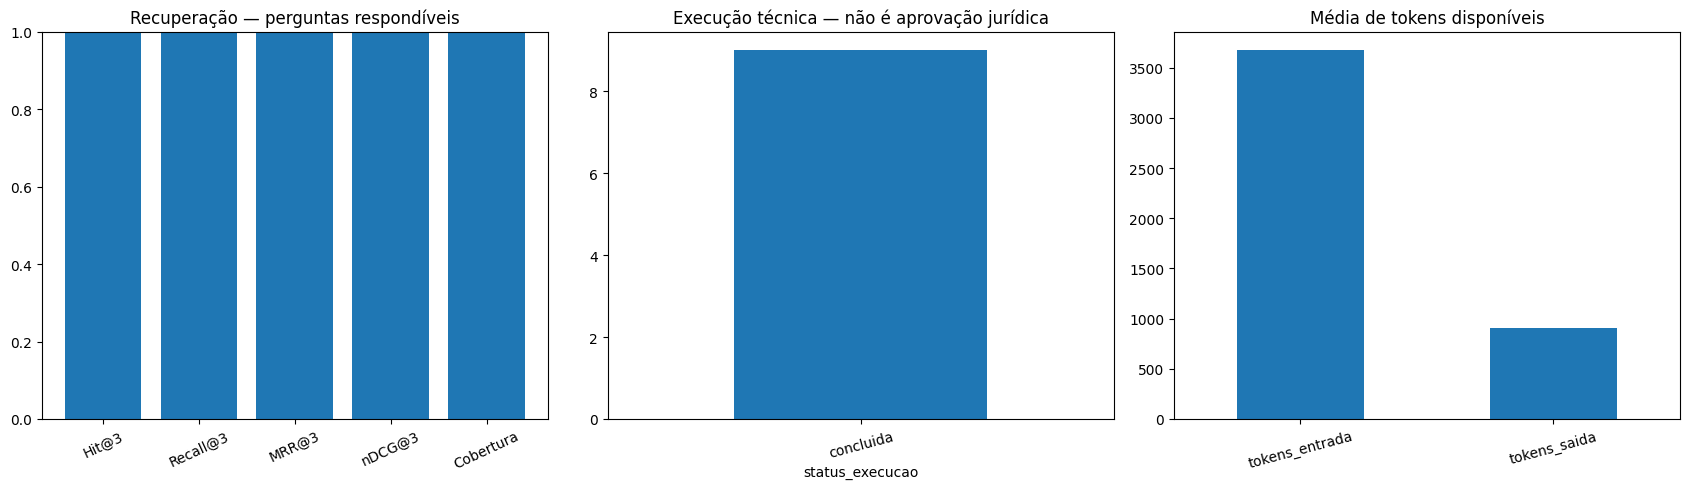

Concluídas: 9 | Falhas: 0
Qualidade jurídica: Revisão humana registrada para todas as saídas originais; observações e correções preservadas. Não representa certificação independente.
Relatórios: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\reports\legislacao\avaliacao_final\2318200177f97e4df627986194bbba9cdaecd7fe2bdd8354fe3293b725734f1e
Resultados do teste não devem orientar novos ajustes apresentados como avaliação cega deste mesmo conjunto.


In [8]:
# Diagnóstico independente: carrega somente arquivos já salvos, sem gerar respostas.
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

DIAGNOSTIC_ROOT_08 = next((base for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (base / 'src/rag/evaluation_08.py').is_file()), None)
if DIAGNOSTIC_ROOT_08 is None:
    raise FileNotFoundError('Raiz do projeto não encontrada para carregar o diagnóstico.')
if str(DIAGNOSTIC_ROOT_08) not in sys.path:
    sys.path.insert(0, str(DIAGNOSTIC_ROOT_08))
import src.rag.evaluation_08 as diagnostic_module_08
importlib.reload(diagnostic_module_08)

diagnostic_frozen_08 = diagnostic_module_08.validate_frozen(DIAGNOSTIC_ROOT_08)
DIAGNOSTIC_REPORT_08: Path = diagnostic_module_08.output_folder(DIAGNOSTIC_ROOT_08, diagnostic_frozen_08)
diagnostic_results_path_08 = DIAGNOSTIC_REPORT_08 / 'respostas_teste.json'
if not diagnostic_results_path_08.is_file():
    raise FileNotFoundError('Não há respostas reais salvas para este diagnóstico. Execute o lote de teste primeiro.')
diagnostic_results_08 = diagnostic_module_08.read(diagnostic_results_path_08)
diagnostic_questions_08, diagnostic_references_08, _ = diagnostic_module_08.load_test(DIAGNOSTIC_ROOT_08)
df_metrics_08, summary_08 = diagnostic_module_08.evaluate(
    DIAGNOSTIC_ROOT_08, diagnostic_frozen_08,
    diagnostic_questions_08, diagnostic_references_08, diagnostic_results_08)

if not summary_08['teste_completo']:
    print('Diagnóstico final ainda indisponível: há perguntas não executadas. Não serão exibidas taxas fictícias.')
else:
    fig_08, axes_08 = plt.subplots(1, 3, figsize=(17, 5))
    metric_names_08 = ['hit', 'recall', 'mrr', 'ndcg', 'cobertura_evidencias']
    metric_values_08 = [summary_08[name] for name in metric_names_08]
    if all(value is not None for value in metric_values_08):
        axes_08[0].bar(['Hit@3', 'Recall@3', 'MRR@3', 'nDCG@3', 'Cobertura'], metric_values_08)
        axes_08[0].set_ylim(0, 1)
        axes_08[0].tick_params(axis='x', rotation=25)
    axes_08[0].set_title('Recuperação — perguntas respondíveis')
    df_metrics_08['status_execucao'].value_counts().plot.bar(ax=axes_08[1], rot=15)
    axes_08[1].set_title('Execução técnica — não é aprovação jurídica')
    token_means_08 = pd.Series({column: pd.to_numeric(df_metrics_08[column], errors='coerce').mean() for column in ('tokens_entrada', 'tokens_saida')}).dropna()
    if not token_means_08.empty:
        token_means_08.plot.bar(ax=axes_08[2], rot=15)
    else:
        axes_08[2].text(0.1, 0.5, 'Sem telemetria de tokens disponível')
    axes_08[2].set_title('Média de tokens disponíveis')
    fig_08.tight_layout()
    fig_08.savefig(DIAGNOSTIC_REPORT_08 / 'diagnostico_final.png', dpi=150)
    plt.show()
    print('Concluídas:', summary_08['concluidas'], '| Falhas:', summary_08['falhas'])
    print('Qualidade jurídica:', summary_08['qualidade_juridica'])
    print('Relatórios:', DIAGNOSTIC_REPORT_08)
    print('Resultados do teste não devem orientar novos ajustes apresentados como avaliação cega deste mesmo conjunto.')


## 8. Revisões concluídas e arquivo de respostas reais

As decisões abaixo se referem às respostas originais do modelo, conforme esclarecido pela revisora. Seus textos finais e observações permanecem integrais nas fichas e no arquivo de feedback. Sugestões de ajuste não são executadas como instruções nem usadas para alterar retroativamente as respostas ou os resultados do teste.

O pacote contém pergunta, resposta real, fontes entregues, decisão humana, critérios e texto final da revisora, com hashes e versões. Os textos com pedidos de conferência ou divergências identificadas ficam sinalizados para curadoria, sem modificar as decisões declaradas. A exportação não treina o modelo nem modifica o prompt congelado. Usar este feedback em ajustes futuros exige outro conjunto de teste para uma avaliação cega da nova versão.


,query_id,decisao_sobre_original,revisor,texto_revisora_preservado,alertas_curadoria
0,q_test_01,aprovada,Laisa,True,
1,q_test_02,aprovada,Laisa,True,
2,q_test_03,reprovada,Laisa,True,Texto da revisora contém pedidos de conferênci...
3,q_test_04,aprovada,Laisa,True,
4,q_test_05,reprovada,Laisa,True,Texto da revisora contém pedidos de conferênci...
5,q_test_06,aprovada,Laisa,True,Texto da revisora contém pedidos de conferênci...
6,q_test_07,aprovada,Laisa,True,Texto da revisora contém pedidos de conferênci...
7,q_test_08,aprovada,Laisa,True,Texto da revisora contém pedidos de conferênci...
8,q_test_neg_02,reprovada,Laisa,True,


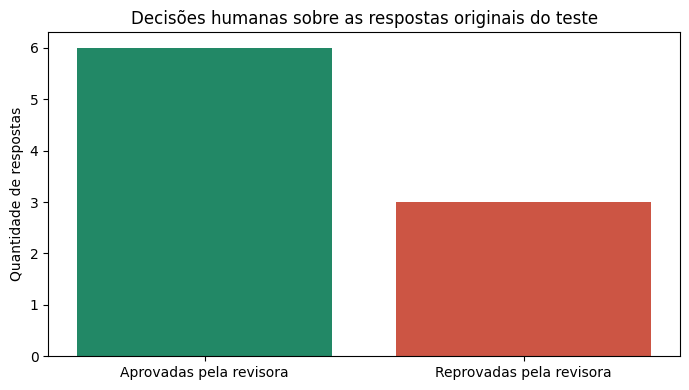

Avaliações registradas: 9
Proporção aprovada pela revisora: 66.7%
Essa proporção não é certificação jurídica independente nem taxa de ausência de alucinação.
Respostas reais e seus textos finais salvos em: data\evaluation\legislacao\feedback_pos_teste\113baf0b957455ddc6d720e68c14f6e30cfaa093484e790068ca239b30de2c9c\respostas_reais_e_feedback.jsonl
Nenhum treino, alteração de pesos, nova resposta ou mudança no prompt foi executado.


In [9]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt

FEEDBACK_ROOT_08 = next((base for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (base / 'src/rag/feedback_08.py').is_file()), None)
if FEEDBACK_ROOT_08 is None:
    raise FileNotFoundError('Módulo de feedback não encontrado.')
if str(FEEDBACK_ROOT_08) not in sys.path:
    sys.path.insert(0, str(FEEDBACK_ROOT_08))
import src.rag.feedback_08 as feedback_module_08
importlib.reload(feedback_module_08)

feedback_records_08, feedback_summary_08 = feedback_module_08.export_feedback(FEEDBACK_ROOT_08)
display(pd.DataFrame([{'query_id': r['query_id'],
    'decisao_sobre_original': r['decisao_sobre_resposta_original'], 'revisor': r['revisor'],
    'texto_revisora_preservado': bool(r['texto_final_informado_pela_revisora']),
    'alertas_curadoria': '; '.join(r['alertas_curadoria'])} for r in feedback_records_08]))

fig_reviews_08, ax_reviews_08 = plt.subplots(figsize=(7, 4))
ax_reviews_08.bar(['Aprovadas pela revisora', 'Reprovadas pela revisora'],
    [feedback_summary_08['aprovadas_pela_revisora'], feedback_summary_08['reprovadas_pela_revisora']],
    color=['#228866', '#cc5544'])
ax_reviews_08.set_title('Decisões humanas sobre as respostas originais do teste')
ax_reviews_08.set_ylabel('Quantidade de respostas')
fig_reviews_08.tight_layout()
plt.show()
print('Avaliações registradas:', feedback_summary_08['revisoes_registradas'])
print('Proporção aprovada pela revisora:', f"{feedback_summary_08['proporcao_aprovada_pela_revisora']:.1%}")
print('Essa proporção não é certificação jurídica independente nem taxa de ausência de alucinação.')
print('Respostas reais e seus textos finais salvos em:', feedback_summary_08['feedback_arquivo'])
print('Nenhum treino, alteração de pesos, nova resposta ou mudança no prompt foi executado.')


## 9. Diagnóstico final consolidado e conclusão

Métricas reais da execução, recuperação e revisão das respostas, com gráficos, limitações e melhorias futuras. Esta célula funciona isoladamente e usa apenas dados já salvos; não chama o modelo nem altera suas respostas ou decisões.


### Métricas das respostas reais e da revisão humana

,indicador,resultado
0,Respostas previstas,9
1,Execução concluída,9/9 (100.0%)
2,Falhas técnicas,0
3,Respostas originais aprovadas pela revisora,6/9 (66.7%)
4,Respostas originais reprovadas pela revisora,3/9 (33.3%)
5,Respostas com alertas formais,3/9
6,Taxa específica de alucinação,Não mensurada por anotação específica; não inf...


,query_id,rotulo_resposta,status_execucao,decisao,fontes_entregues,alertas_formais,tokens_entrada,tokens_saida,tempo_total_observado_ms
0,q_test_01,respondível,concluida,aprovada,3,0,3838,686,193591.4370
1,q_test_02,respondível,concluida,aprovada,3,0,4794,843,250674.7589
2,q_test_03,respondível,concluida,reprovada,3,0,2705,1061,159707.2387
3,q_test_04,respondível,concluida,aprovada,3,0,2512,979,190379.5769
4,q_test_05,sem_resposta,concluida,reprovada,3,1,5116,310,252532.7039
5,q_test_06,respondível,concluida,aprovada,3,0,4262,1253,241571.1299
6,q_test_07,respondível,concluida,aprovada,2,1,3218,1125,243539.9625
7,q_test_08,respondível,concluida,aprovada,3,0,4049,1610,289414.7389
8,q_test_neg_02,sem_resposta,concluida,reprovada,3,1,2576,322,233817.3279


### Aprovação por tipo de caso

decisao,aprovada,reprovada
rotulo_resposta,,
respondível,6,1
sem_resposta,0,2


### Volume e tempo observado

,indicador,valor
0,Média de tokens de entrada,3674.444444
1,Média de tokens de saída,909.888889
2,Fontes entregues — média por pergunta,2.888889
3,Tempo total observado — média em segundos,228.358764
4,Tempo total observado — mediana em segundos,241.571130
5,Tempo total observado — máximo em segundos,289.414739
6,Respostas que reutilizaram cache de geração,0.000000


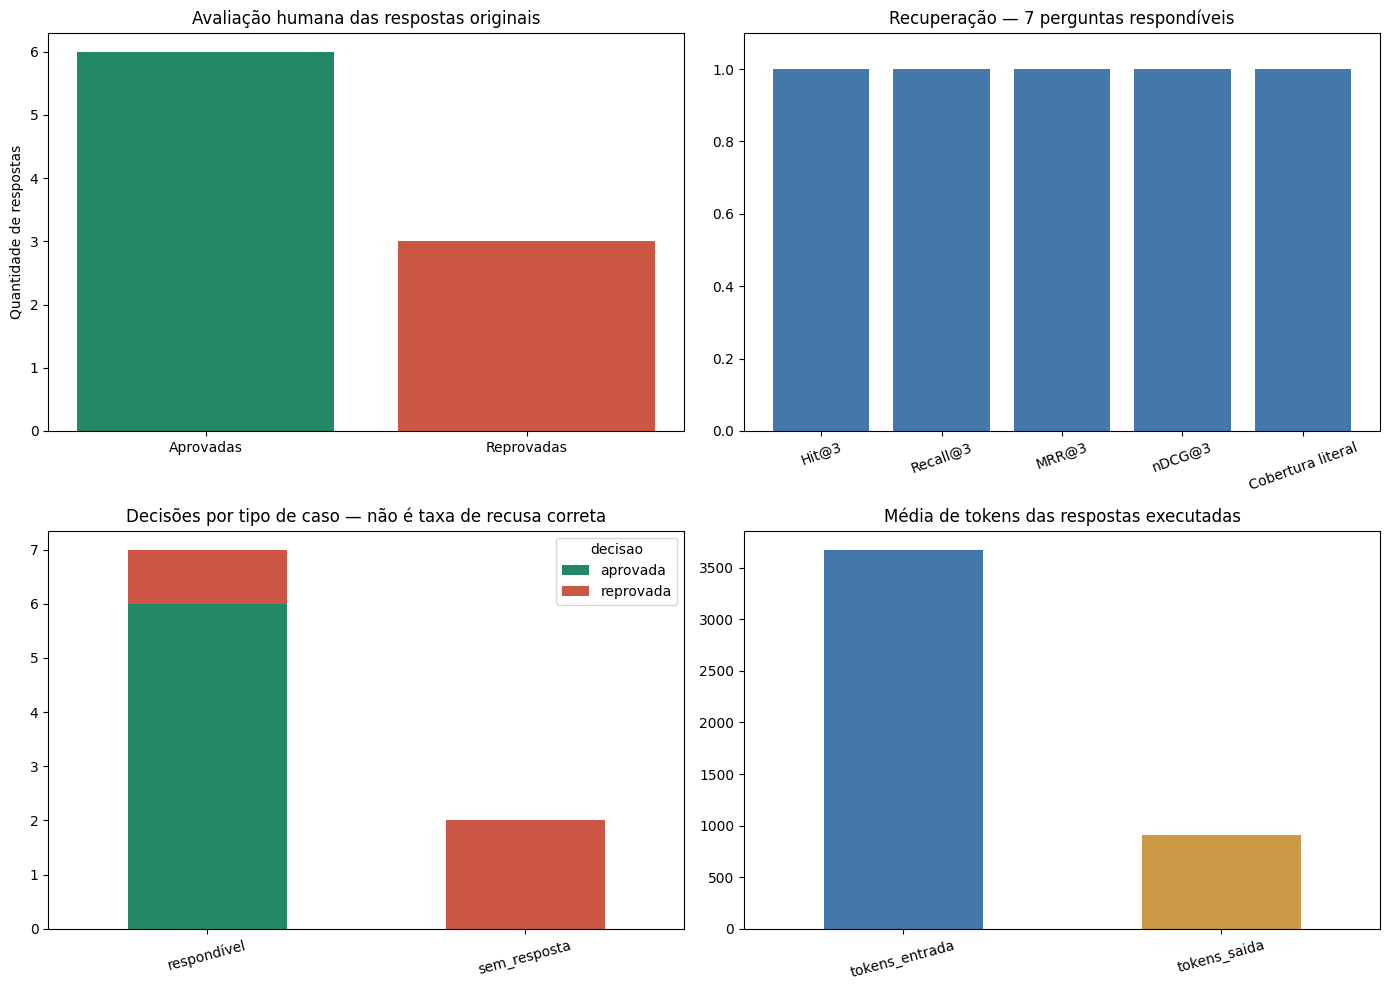

### Análise e conclusão final

O pipeline concluiu **9 de 9 respostas**, com **0 falhas técnicas**.
Nas **7 perguntas respondíveis**, o Recall@3 foi **100.0%**,
o MRR@3 foi **1.000**, o nDCG@3 foi **1.000**
e a cobertura literal das evidências foi **100.0%**.
Essas medidas dizem respeito às fontes efetivamente entregues, depois da deduplicação e do orçamento de contexto.
Os **2 casos sem resposta** não recebem acerto artificial de recuperação.

A revisora aprovou **6 respostas originais (66.7%)** e reprovou
**3 (33.3%)**: **q_test_03, q_test_05, q_test_neg_02**.
As nove avaliações estão registradas; reprovação é uma decisão concluída, não ausência de revisão.
As observações e respostas finais da revisora foram preservadas separadamente das saídas originais.

O contraste entre a recuperação e a aprovação humana mostra que localizar o dispositivo esperado
não garante uma explicação correta ou uma conduta adequada. As revisões registraram problemas de
referências aos dispositivos, afirmações sem suporte, repetições, limitações genéricas e classificação
indevida de perguntas como fora do escopo. São achados qualitativos das fichas; não uma contagem
automática de erros por categoria. Alertas de citação também não comprovam alucinação.

**Limitações:** este é um piloto com apenas 9 perguntas, uma configuração e revisão humana
com ressalvas documentadas. A cobertura literal pode ser favorecida pelo envio de artigos completos.
A aprovação humana não é certificação jurídica independente. Os tempos refletem o equipamento e o uso
de cache observado. Não houve anotação específica suficiente para informar uma taxa de alucinação
ou de recusa correta; esses indicadores não são presumidos como zero.

**Melhorias futuras:** serão feitas melhorias na formulação, diversidade e clareza das perguntas,
assim como na precisão, fundamentação, concisão e adequação das respostas geradas. O trabalho incluirá
curadoria das correções propostas, revisão das remissões legais, tratamento de informações insuficientes
e distinção entre tema fora do escopo e ausência de evidência. Ajustes de prompt ou do modelo serão
versionados e avaliados separadamente. O feedback salvo é insumo para essa curadoria, sem treinamento
automático nem alteração dos resultados originais.

Se estas perguntas ou correções forem utilizadas para melhorar o sistema, será necessário **um novo
conjunto de teste independente** para avaliar a nova versão. O diagnóstico atual permanece como
registro da versão congelada e das decisões efetivamente realizadas.


2539

In [10]:
# Diagnóstico final independente: usa respostas reais e avaliações já registradas.
from pathlib import Path
import sys
import importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython.core.display import Markdown

CONCLUSION_ROOT_08 = next((base for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (base / 'src/rag/evaluation_08.py').is_file()), None)
if CONCLUSION_ROOT_08 is None:
    raise FileNotFoundError('Raiz do projeto não encontrada.')
if str(CONCLUSION_ROOT_08) not in sys.path:
    sys.path.insert(0, str(CONCLUSION_ROOT_08))
import src.rag.evaluation_08 as final_evaluation_08
import src.rag.review_08 as final_review_08
importlib.reload(final_evaluation_08)
importlib.reload(final_review_08)

final_config_08 = final_evaluation_08.validate_frozen(CONCLUSION_ROOT_08)
final_directory_08: Path = final_evaluation_08.output_folder(CONCLUSION_ROOT_08, final_config_08)
final_responses_path_08 = final_directory_08 / 'respostas_teste.json'
if not final_responses_path_08.is_file():
    raise FileNotFoundError('Não há respostas reais salvas para o diagnóstico final.')
final_responses_08 = final_evaluation_08.read(final_responses_path_08)
final_human_08 = final_review_08.save_notebook_reviews(CONCLUSION_ROOT_08)
final_questions_08, final_refs_08, _ = final_evaluation_08.load_test(CONCLUSION_ROOT_08)
final_metrics_08, final_summary_08 = final_evaluation_08.evaluate(
    CONCLUSION_ROOT_08, final_config_08, final_questions_08, final_refs_08, final_responses_08)

if not final_summary_08['teste_completo']:
    raise ValueError('O teste ainda está incompleto; não produzir conclusão final.')
final_by_id_08 = {r['query_id']: r for r in final_responses_08}
final_valid_reviews_08 = [r for r in final_human_08
    if r['query_id'] in final_by_id_08 and r['resposta_sha256'] == final_by_id_08[r['query_id']]['resposta_sha256']
    and r['configuracao_sha256'] == final_config_08['configuracao_sha256']
    and r['decisao'] in ('aprovada', 'reprovada') and r['revisor']]
if len(final_valid_reviews_08) != len(final_questions_08):
    raise ValueError('Há resposta sem decisão humana correspondente; conferir as fichas salvas.')

final_review_frame_08 = pd.DataFrame(final_valid_reviews_08)
final_table_08 = final_metrics_08.merge(
    final_review_frame_08[['query_id', 'decisao', 'revisor']], on='query_id', validate='one_to_one')
final_total_08 = len(final_table_08)
final_approved_08 = int(final_table_08['decisao'].eq('aprovada').sum())
final_rejected_08 = int(final_table_08['decisao'].eq('reprovada').sum())
final_alerts_08 = int(final_table_08['alertas_formais'].fillna(0).gt(0).sum())
final_approval_rate_08 = final_approved_08 / final_total_08
final_execution_rate_08 = final_summary_08['concluidas'] / final_total_08
final_rejected_ids_08 = final_table_08.loc[final_table_08['decisao'].eq('reprovada'), 'query_id'].tolist()

display(Markdown('### Métricas das respostas reais e da revisão humana'))
display(pd.DataFrame([
    {'indicador': 'Respostas previstas', 'resultado': str(final_total_08)},
    {'indicador': 'Execução concluída', 'resultado': f"{final_summary_08['concluidas']}/{final_total_08} ({final_execution_rate_08:.1%})"},
    {'indicador': 'Falhas técnicas', 'resultado': str(final_summary_08['falhas'])},
    {'indicador': 'Respostas originais aprovadas pela revisora', 'resultado': f'{final_approved_08}/{final_total_08} ({final_approval_rate_08:.1%})'},
    {'indicador': 'Respostas originais reprovadas pela revisora', 'resultado': f'{final_rejected_08}/{final_total_08} ({final_rejected_08 / final_total_08:.1%})'},
    {'indicador': 'Respostas com alertas formais', 'resultado': f'{final_alerts_08}/{final_total_08}'},
    {'indicador': 'Taxa específica de alucinação', 'resultado': 'Não mensurada por anotação específica; não inferida da reprovação ou dos alertas.'}
]))
display(final_table_08[['query_id', 'rotulo_resposta', 'status_execucao', 'decisao',
    'fontes_entregues', 'alertas_formais', 'tokens_entrada', 'tokens_saida', 'tempo_total_observado_ms']])

final_group_08 = pd.crosstab(final_table_08['rotulo_resposta'], final_table_08['decisao']).reindex(
    columns=['aprovada', 'reprovada'], fill_value=0)
display(Markdown('### Aprovação por tipo de caso'))
display(final_group_08)

final_times_08 = pd.Series(pd.to_numeric(final_table_08['tempo_total_observado_ms'], errors='coerce'), index=final_table_08.index, dtype='float64') / 1000
final_tokens_08 = final_table_08[['tokens_entrada', 'tokens_saida']].apply(pd.to_numeric, errors='coerce')
display(Markdown('### Volume e tempo observado'))
display(pd.DataFrame([
    {'indicador': 'Média de tokens de entrada', 'valor': final_tokens_08['tokens_entrada'].mean()},
    {'indicador': 'Média de tokens de saída', 'valor': final_tokens_08['tokens_saida'].mean()},
    {'indicador': 'Fontes entregues — média por pergunta', 'valor': final_table_08['fontes_entregues'].mean()},
    {'indicador': 'Tempo total observado — média em segundos', 'valor': final_times_08.mean()},
    {'indicador': 'Tempo total observado — mediana em segundos', 'valor': final_times_08.median()},
    {'indicador': 'Tempo total observado — máximo em segundos', 'valor': final_times_08.max()},
    {'indicador': 'Respostas que reutilizaram cache de geração', 'valor': int(final_table_08['cache_hit'].eq(True).sum())}
]))

fig_final_08, axes_final_08 = plt.subplots(2, 2, figsize=(14, 10))
axes_final_08[0, 0].bar(['Aprovadas', 'Reprovadas'], [final_approved_08, final_rejected_08], color=['#228866', '#cc5544'])
axes_final_08[0, 0].set_title('Avaliação humana das respostas originais')
axes_final_08[0, 0].set_ylabel('Quantidade de respostas')
final_metric_labels_08 = ['Hit@3', 'Recall@3', 'MRR@3', 'nDCG@3', 'Cobertura literal']
final_metric_keys_08 = ['hit', 'recall', 'mrr', 'ndcg', 'cobertura_evidencias']
axes_final_08[0, 1].bar(final_metric_labels_08, [final_summary_08[k] for k in final_metric_keys_08], color='#4477aa')
axes_final_08[0, 1].set_ylim(0, 1.1)
axes_final_08[0, 1].tick_params(axis='x', rotation=20)
axes_final_08[0, 1].set_title(f"Recuperação — {final_summary_08['perguntas_respondiveis']} perguntas respondíveis")
final_group_08.plot.bar(stacked=True, ax=axes_final_08[1, 0], color=['#228866', '#cc5544'], rot=15)
axes_final_08[1, 0].set_title('Decisões por tipo de caso — não é taxa de recusa correta')
axes_final_08[1, 0].set_xlabel('')
pd.Series({column: final_tokens_08[column].mean() for column in final_tokens_08.columns}).plot.bar(ax=axes_final_08[1, 1], color=['#4477aa', '#cc9944'], rot=15)
axes_final_08[1, 1].set_title('Média de tokens das respostas executadas')
fig_final_08.tight_layout()
fig_final_08.savefig(final_directory_08 / 'diagnostico_conclusao_final.png', dpi=150)
plt.show()

final_analysis_08 = f"""### Análise e conclusão final

O pipeline concluiu **{final_summary_08['concluidas']} de {final_total_08} respostas**, com **{final_summary_08['falhas']} falhas técnicas**.
Nas **{final_summary_08['perguntas_respondiveis']} perguntas respondíveis**, o Recall@3 foi **{final_summary_08['recall']:.1%}**,
o MRR@3 foi **{final_summary_08['mrr']:.3f}**, o nDCG@3 foi **{final_summary_08['ndcg']:.3f}**
e a cobertura literal das evidências foi **{final_summary_08['cobertura_evidencias']:.1%}**.
Essas medidas dizem respeito às fontes efetivamente entregues, depois da deduplicação e do orçamento de contexto.
Os **{final_summary_08['casos_sem_resposta']} casos sem resposta** não recebem acerto artificial de recuperação.

A revisora aprovou **{final_approved_08} respostas originais ({final_approval_rate_08:.1%})** e reprovou
**{final_rejected_08} ({final_rejected_08 / final_total_08:.1%})**: **{', '.join(final_rejected_ids_08)}**.
As nove avaliações estão registradas; reprovação é uma decisão concluída, não ausência de revisão.
As observações e respostas finais da revisora foram preservadas separadamente das saídas originais.

O contraste entre a recuperação e a aprovação humana mostra que localizar o dispositivo esperado
não garante uma explicação correta ou uma conduta adequada. As revisões registraram problemas de
referências aos dispositivos, afirmações sem suporte, repetições, limitações genéricas e classificação
indevida de perguntas como fora do escopo. São achados qualitativos das fichas; não uma contagem
automática de erros por categoria. Alertas de citação também não comprovam alucinação.

**Limitações:** este é um piloto com apenas {final_total_08} perguntas, uma configuração e revisão humana
com ressalvas documentadas. A cobertura literal pode ser favorecida pelo envio de artigos completos.
A aprovação humana não é certificação jurídica independente. Os tempos refletem o equipamento e o uso
de cache observado. Não houve anotação específica suficiente para informar uma taxa de alucinação
ou de recusa correta; esses indicadores não são presumidos como zero.

**Melhorias futuras:** serão feitas melhorias na formulação, diversidade e clareza das perguntas,
assim como na precisão, fundamentação, concisão e adequação das respostas geradas. O trabalho incluirá
curadoria das correções propostas, revisão das remissões legais, tratamento de informações insuficientes
e distinção entre tema fora do escopo e ausência de evidência. Ajustes de prompt ou do modelo serão
versionados e avaliados separadamente. O feedback salvo é insumo para essa curadoria, sem treinamento
automático nem alteração dos resultados originais.

Se estas perguntas ou correções forem utilizadas para melhorar o sistema, será necessário **um novo
conjunto de teste independente** para avaliar a nova versão. O diagnóstico atual permanece como
registro da versão congelada e das decisões efetivamente realizadas.
"""
display(Markdown(final_analysis_08))
final_evaluation_08.write(final_directory_08 / 'conclusao_final_metricas.json', {
    'configuracao_sha256': final_config_08['configuracao_sha256'],
    'respostas_originais_avaliadas': final_total_08,
    'aprovadas': final_approved_08, 'reprovadas': final_rejected_08,
    'proporcao_aprovada_pela_revisora': final_approval_rate_08,
    'metricas_recuperacao': {k: final_summary_08[k] for k in final_metric_keys_08},
    'respostas_com_alerta_formal': final_alerts_08,
    'taxa_alucinacao': None, 'taxa_recusa_correta': None})
(final_directory_08 / 'conclusao_final.md').write_text(final_analysis_08, encoding='utf-8')
